# 16 · Réseaux feed-forward — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/ch16_feedforward/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | 16.Q1 à 16.Q10, 16.R1 à 16.R3, 16.1 à 16.5, 16.7, 16.8 | vérifier tes réponses courtes | 🧠 🔁 ✏️ ∂ 🧮 | ★ à ★★★ | |
| A | 16.11 | Prédire les formes des sorties avant d'exécuter | 🔮 | ★ | 10 |
|  | 16.12 | Compter les paramètres par programme : count_parameters | 🔨 | ★ | 10 |
|  | 16.13 | La couche dense : dense_forward | 🔨 | ★ | 15 |
| B | 16.14 | Dix façons d'initialiser : init_weights | 🔨 | ★★ | 25 |
|  | 16.15 | Reproduire les figures 16.5 et 16.6, puis comparer Glorot et He | 🎨 | ★★ | 20 |
|  | 16.16 | Ordre topologique d'un graphe : topological_order | 🔨 | ★★ | 25 |
| C | 16.17 | Empiler les couches : init_mlp et mlp_forward | 🔨 | ★★ | 30 |
|  | 16.18 | Relire un MLPClassifier de scikit-learn avec ton mlp_forward | 📦 | ★★ | 25 |
|  | 16.19 | Initialisation constante : les neurones restent-ils jumeaux ? | 🔮 | ★★ | 20 |
|  | 16.20 | Chasse au bug : transposée, biais mal diffusé, variance prise pour un écart-type | 🐛 | ★★ | 25 |
|  | 16.21 | Rendre l'aléatoire reproductible et le prouver avec pytest | 🛠️ | ★★ | 20 |
| D | 16.22 | Lire des histogrammes d'activations couche par couche | 📈 | ★★ | 20 |
|  | 16.23 | Activations à travers 20 couches selon l'initialisation | 🔬 | ★★★ | 45 |
|  | 16.24 | Défi : garder vivant un réseau ReLU de 50 couches | 🏆 | ★★★ | 60 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.13 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Suivre la forme de chaque tableau d'une passe avant matricielle, et compter les paramètres d'un réseau dense.
- Écrire et vérifier contre PyTorch, scikit-learn et la bibliothèque standard les fonctions de `mylearn.nn.layers` : `count_parameters`, `dense_forward`, `init_weights`, `topological_order`, `init_mlp` et `mlp_forward`.
- Voir pourquoi une initialisation constante ne marche pas, et ce que changent LeCun, Glorot et He.
- Diagnostiquer, couche par couche, des activations qui s'évanouissent, explosent ou saturent.

**Rappel express.** Une couche : $\mathbf{Z} = \mathbf{X}\mathbf{W} + \mathbf{b}$, avec $\mathbf{X}$ $(n, n_{in})$, $\mathbf{W}$ $(n_{in}, n_{out})$, $\mathbf{b}$ $(n_{out},)$ ; un MLP : $\mathbf{A}^{(\ell)} = f(\mathbf{A}^{(\ell-1)}\mathbf{W}^{(\ell)} + \mathbf{b}^{(\ell)})$, $\mathbf{A}^{(0)} = \mathbf{X}$ ; paramètres : $P = \sum_\ell (n_{\ell-1} n_\ell + n_\ell)$ ; variance d'une somme pondérée : $\mathrm{Var}(z) = n_{in}\,\mathrm{Var}(w)\,\mathbb{E}[x^2]$ ; LeCun $\mathrm{Var}(w) = 1/n_{in}$, Glorot $2/(n_{in} + n_{out})$, He $2/n_{in}$ ; $\mathcal{U}(-a, a)$ a l'écart-type $a/\sqrt{3}$. En NumPy : `X @ W + b`, `rng = np.random.default_rng(seed)`, `rng.normal(0.0, std, size)`, `rng.uniform(-a, a, size)` ; en PyTorch, `nn.Linear(n_in, n_out)` range ses poids en `(n_out, n_in)`.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ 16.1 à 16.5, ∂ 16.7 et 🧮 16.8)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"E"`) ; des nœuds ou une suite de codes : les lettres collées, dans l'ordre (`"XYZ"`) ; une forme NumPy : entre guillemets (`"(4, 7)"`, `"(7,)"`), ou `"erreur"` ; plusieurs nombres : une liste (`[4, 7]`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », la preuve ∂ 16.6, les démonstrations de ∂ 16.7, la réflexion (🗣️ 16.9, 📄 16.10) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import heapq
import itertools
import math

import numpy as np


def count(sizes, bias=True):
    """Parameters of a dense network [n_0, n_1, ..., n_L]."""
    return sum(a * b + (b if bias else 0) for a, b in zip(sizes[:-1], sizes[1:]))


def kahn(edges, nodes):
    """Kahn's algorithm, the smallest ready node first."""
    parents = {v: 0 for v in nodes}
    for _, child in edges:
        parents[child] += 1
    ready = [v for v in nodes if parents[v] == 0]
    heapq.heapify(ready)
    order = []
    while ready:
        node = heapq.heappop(ready)
        order.append(node)
        for parent, child in edges:
            if parent == node:
                parents[child] -= 1
                if parents[child] == 0:
                    heapq.heappush(ready, child)
    return order                      # shorter than nodes when the graph has a cycle


def n_orders(edges, nodes):
    """Number of topological orders (brute force on the permutations)."""
    return sum(all(p.index(a) < p.index(b) for a, b in edges) for p in itertools.permutations(nodes))


def descendants(edges, start):
    found, todo = set(), [start]
    while todo:
        node = todo.pop()
        for parent, child in edges:
            if parent == node and child not in found:
                found.add(child)
                todo.append(child)
    return "".join(sorted(found))


# Q2: the graph of the statement
EDGES_Q2 = [("A", "C"), ("B", "C"), ("C", "D"), ("C", "E"), ("B", "E")]

# 16.2: the 2-2-1 network
X_162 = np.array([2.0, 1.0])
W1_162 = np.array([[0.5, -1.0], [1.0, 0.5]])
B1_162 = np.array([0.0, 1.0])
W2_162 = np.array([[1.5], [-2.0]])
B2_162 = np.array([-0.5])


def out_162(x, f):
    return (f(np.asarray(x) @ W1_162 + B1_162) @ W2_162 + B2_162)[..., 0]


def relu(z):
    return np.maximum(0.0, z)


# 16.3: the cache of a 784-256-64-10 network on a batch of 32
SIZES_163 = [784, 256, 64, 10]
CACHE_163 = sum(32 * a + 32 * b for a, b in zip(SIZES_163[:-1], SIZES_163[1:]))

# 16.4: the graph of the statement
NODES_164 = list("UVABCY")
EDGES_164 = [("U", "A"), ("V", "A"), ("V", "B"), ("A", "C"), ("B", "C"), ("A", "Y"), ("C", "Y")]


def longest_path(edges, nodes):
    order = kahn(edges, nodes)
    best = {v: 0 for v in nodes}
    for node in order:
        for parent, child in edges:
            if parent == node:
                best[child] = max(best[child], best[node] + 1)
    return max(best.values())


# 16.5: the node S and its messages (time, input, value)
MESSAGES_165 = [(2, "P", 1), (3, "Q", 4), (5, "R", 2), (6, "P", 7), (8, "Q", 0), (9, "R", 3), (10, "P", 2)]


def stamped_165():
    """The rule of the book: recompute when the three inputs are stamped after the last computation."""
    values, stamps, last, outputs = {"P": 3, "Q": 5, "R": 2}, {"P": 1, "Q": 1, "R": 1}, 1, []
    for t, name, value in MESSAGES_165:
        values[name], stamps[name] = value, t
        if all(s > last for s in stamps.values()):
            last = t
            outputs.append((t, sum(values.values())))
    return outputs


def naive_165():
    """Recompute whenever an input changes its value."""
    values, outputs = {"P": 3, "Q": 5, "R": 2}, []
    for t, name, value in MESSAGES_165:
        if value != values[name]:
            values[name] = value
            outputs.append((t, sum(values.values())))
    return outputs


# 16.8: the MLP 784-512-512-10 on MNIST
SIZES_168 = [784, 512, 512, 10]
MULTS_168 = sum(a * b for a, b in zip(SIZES_168[:-1], SIZES_168[1:]))
CACHE_168 = sum(128 * a + 128 * b for a, b in zip(SIZES_168[:-1], SIZES_168[1:]))

**16.Q1 — Qu'est-ce qui rend un réseau « feed-forward » ?**

In [3]:
wb.record("16.Q1a", True, mistakes={"relis la règle du §16.2 : une donnée peut-elle revenir à un nœud qu'elle a quitté dans un réseau sans boucle ?": False})
wb.record("16.Q1b", "B", mistakes={"la « couche d'entrée » ne fait que tenir les données : a-t-elle des poids ?": "A",
          "combien de matrices de poids entre 784, 128 et 10 ?": "C",
          "128 est la largeur de la couche cachée, pas un nombre de couches": "D"})
wb.record("16.Q1c", False, mistakes={"relis le §16.1 : dans la plupart des réseaux, les neurones d'une même couche communiquent-ils ?": True})
wb.record("16.Q1d", True, mistakes={"relis le §16.1 : sur quoi chaque couche construit-elle son calcul ?": False})

WB_ANSWER {"hash": "9ab8711bb11b875e7fc9c2c09d9d024d58f8870f929fbff604cfa9d92080a198", "id": "16.Q1a", "kind": "bool", "mistakes": {"4b70c8e485bb8b3f49811e0c091e42e7f79dadc747d7a72d4a9a21d01ee4bd44": "relis la règle du §16.2 : une donnée peut-elle revenir à un nœud qu'elle a quitté dans un réseau sans boucle ?"}}
📝 Ex 16.Q1a : réponse enregistrée (bool).
WB_ANSWER {"hash": "a5db13d5a34d89e5a9d45a511fb6b59a8f9fab06a7e4a44357ba0f35068860f7", "id": "16.Q1b", "kind": "str", "mistakes": {"09e8c7b01f4e70ee214228392b71911b2e18a807163771c6d59036469c77862f": "la « couche d'entrée » ne fait que tenir les données : a-t-elle des poids ?", "b45e5bf1cfe144b26a725ab78facb1aa3980af1d396b754e0efe199e2638dfb4": "128 est la largeur de la couche cachée, pas un nombre de couches", "e5308b10ec2f4be89bb78e2e77fcd818356647b0ff7a5705c6dc5d7783aec417": "combien de matrices de poids entre 784, 128 et 10 ?"}}
📝 Ex 16.Q1b : réponse enregistrée (str).
WB_ANSWER {"hash": "b3763a812b970837bd2b1b119cb9d92c817fea7bff27

**16.Q2 — Vocabulaire des graphes : nœuds, arêtes, parents, descendants**

In [4]:
wb.record("16.Q2a", "".join(sorted(p for p, c in EDGES_Q2 if c == "E")), mistakes={"il manque un parent : relis toutes les arêtes qui arrivent à E": "C",
          "les parents de E sont les nœuds d'où part une arête vers E, pas tous ses ancêtres": "ABC"})
wb.record("16.Q2b", descendants(EDGES_Q2, "A"), mistakes={"un descendant est un nœud où mène un CHEMIN, pas seulement une arête : suis les flèches au-delà de C": "C",
          "A n'est pas son propre descendant": "ACDE"})
wb.record("16.Q2c", len({p for p, _ in EDGES_Q2} - {c for _, c in EDGES_Q2}), mistakes={"cherche les nœuds où n'arrive aucune flèche": 1, "un nœud sans parent n'a aucune flèche qui arrive : D et E en ont": 4})
wb.record("16.Q2d", "D" in descendants(EDGES_Q2, "B"), mistakes={"un ancêtre n'est pas forcément un parent : existe-t-il un chemin de B à D ?": False})
wb.record("16.Q2e", True, mistakes={"relis le §16.2 : quelle convention vaut quand les pointes des flèches sont omises ?": False})

WB_ANSWER {"hash": "5406ac0fb821774387780b3143f1875705d09776cb3a370f2a39cbae2676ee1c", "id": "16.Q2a", "kind": "str", "mistakes": {"977710b155d0ebce300a46467adb65f2156df5843ad5510b3f646a908417dc2f": "les parents de E sont les nœuds d'où part une arête vers E, pas tous ses ancêtres", "d1c6464100a3b2aeb599f1e3ea7a708d321b145ed3c6bfe2bce40b883d09e50e": "il manque un parent : relis toutes les arêtes qui arrivent à E"}}
📝 Ex 16.Q2a : réponse enregistrée (str).
WB_ANSWER {"hash": "94c5ebf4d1de3a77a536e7d16440c838f4cbc0bd462a7cbf63b9acfe24e61df5", "id": "16.Q2b", "kind": "str", "mistakes": {"450f4d92ccdcfa20910674aac9fe3faeb1372b59c70ebde9e6cba128d7dd05db": "A n'est pas son propre descendant", "81ed6f024a2a18427e6adbf90eb337a930dbe9fffbf9105fb1c49ca7283d410a": "un descendant est un nœud où mène un CHEMIN, pas seulement une arête : suis les flèches au-delà de C"}}
📝 Ex 16.Q2b : réponse enregistrée (str).
WB_ANSWER {"hash": "077be951fcbd2cee326b0fb21acc173505887ca63a332190731efcade26a4aa8", "id

**16.Q3 — Vrai ou faux : la passe arrière crée une boucle de rétroaction**

In [5]:
wb.record("16.Q3a", False, mistakes={"la passe arrière parcourt les arêtes à l'envers : un nœud reçoit-il pour autant sa propre sortie comme entrée ?": True})
wb.record("16.Q3b", True, mistakes={"relis la fin du §16.2 : à quel cas le livre réserve-t-il le mot feedback ?": False})
wb.record("16.Q3c", "B", mistakes={"le son du haut-parleur revient dans le micro, qui le renvoie au haut-parleur : est-ce un parcours du graphe à l'envers, ou une boucle ?": "A",
          "y a-t-il une horloge dans cet exemple ?": "C", "y a-t-il des messages horodatés dans cet exemple ?": "D"})

WB_ANSWER {"hash": "f17b07925b887df59aee3416c08af370b1552770eaa4aa35ca0c3832c7312305", "id": "16.Q3a", "kind": "bool", "mistakes": {"785bf17cad2da8130fe91dc98d8116508e34c822b510f561b4c341ec05dadfd2": "la passe arrière parcourt les arêtes à l'envers : un nœud reçoit-il pour autant sa propre sortie comme entrée ?"}}
📝 Ex 16.Q3a : réponse enregistrée (bool).
WB_ANSWER {"hash": "83de5bd42e0cf77b56452a43f11fb0b8602b95efd2abe568cd67b824b8379170", "id": "16.Q3b", "kind": "bool", "mistakes": {"0d2010db273ab793f649c1d15b832b4f1565eddf2c429505aac0690419878ab7": "relis la fin du §16.2 : à quel cas le livre réserve-t-il le mot feedback ?"}}
📝 Ex 16.Q3b : réponse enregistrée (bool).
WB_ANSWER {"hash": "cffe8fd1a077c12f0d302ec0672e1cabe79028f41d4ec75a06d1f63a1c14c2df", "id": "16.Q3c", "kind": "str", "mistakes": {"116240c16b7b95457c600431ea62c4567118d81c119d6d8029101d1f323036e5": "le son du haut-parleur revient dans le micro, qui le renvoie au haut-parleur : est-ce un parcours du graphe à l'envers, o

**16.Q4 — Pourquoi des graphes sans boucle, et où est l'exception des RNN ?**

In [6]:
wb.record("16.Q4a", True, mistakes={"deux chemins parallèles de A à B forment-ils un cycle ? Un cycle revient à son point de départ": False})
wb.record("16.Q4b", "B", mistakes={"supprimer la boucle, c'est supprimer la mémoire du réseau : relis l'exception du §16.2": "A",
          "inverser toutes les flèches garde-t-il la boucle ?": "C",
          "relis la fin du paragraphe sur le DAG (§16.2) : que fait-on pour redessiner un RNN ?": "D"})
wb.record("16.Q4c", True, mistakes={"si chaque nœud avait un parent, en remontant de parent en parent dans un graphe fini, que finirait-on par trouver ?": False})
wb.record("16.Q4d", math.comb(4, 2), mistakes={"chaque paire de nœuds peut avoir au plus UNE arête, sinon il y aurait un cycle de deux arêtes": 12,
          "range les nœuds dans un ordre : chaque nœud peut-il envoyer une arête à TOUS ceux qui viennent après lui ?": 3,
          "compte les paires de nœuds distincts": 4, "une arête d'un nœud vers lui-même est exclue": 10, "16 couples ordonnés, c'est trop : une paire au plus une fois, et pas de boucle": 16})

WB_ANSWER {"hash": "c1bae7f13d27ee473bf548707f40aaf2d87b1cde22751c51410cec8e9ef8d227", "id": "16.Q4a", "kind": "bool", "mistakes": {"d1b72e81e46e140dfe187516c178171defd060d220de8400a887345fa16134b2": "deux chemins parallèles de A à B forment-ils un cycle ? Un cycle revient à son point de départ"}}
📝 Ex 16.Q4a : réponse enregistrée (bool).
WB_ANSWER {"hash": "19d7277b30d7b7e0e2994539d4c57dd25ce508d238e4cd6202572d3f8be04920", "id": "16.Q4b", "kind": "str", "mistakes": {"2e5146682f55d0f63de7accd516accefa4716ead53415e026df44c6a51a1e332": "inverser toutes les flèches garde-t-il la boucle ?", "becff20fb3688b949336dd00a69adb0c07e49b956c24214d0a3d4d47b8bceae8": "relis la fin du paragraphe sur le DAG (§16.2) : que fait-on pour redessiner un RNN ?", "e769e0efde9a963589522f98ae6f8c7301d5b5e6ba74bacd65caed41c94340db": "supprimer la boucle, c'est supprimer la mémoire du réseau : relis l'exception du §16.2"}}
📝 Ex 16.Q4b : réponse enregistrée (str).
WB_ANSWER {"hash": "81d1d5af4f52a03c05ae35a431b16b

**16.Q5 — Réseau synchrone ou asynchrone : reconnaître les deux**

In [7]:
wb.record("16.Q5a", "SAAS", mistakes={"le tableur recalcule-t-il au battement d'une horloge, ou dès qu'une valeur change ?": "SASS",
          "les joueurs révèlent-ils leur coup quand ils veulent, ou au même signal ?": "SAAA",
          "des musiciens qui suivent tous la même battue : y a-t-il un signal commun ?": "AAAS",
          "relis le tableau du §16.3 : qu'est-ce qui déclenche les envois dans chaque système ?": "ASSA"})
wb.record("16.Q5b", False, mistakes={"si l'horloge battait au rythme du plus rapide, le plus lent aurait-il fini son calcul ?": True})
wb.record("16.Q5c", True, mistakes={"relis le §16.3 : lequel des deux cas est le plus général ?": False})

WB_ANSWER {"hash": "2385afc30ab954ade7ac53c577584acc5f3229245f263c8e776d188bfe6ccbdb", "id": "16.Q5a", "kind": "str", "mistakes": {"3b2d1780336883476ad108ba6e38d87383912b50a2babb6d12d79c4e6628d2e4": "relis le tableau du §16.3 : qu'est-ce qui déclenche les envois dans chaque système ?", "4dc5f4975a8de9bd9c563780ee3f56fe35377c5e3b47cad916122e956ffc615c": "le tableur recalcule-t-il au battement d'une horloge, ou dès qu'une valeur change ?", "7b3ba2037080710a5269284620552069da45de36102b30d6321e21430787225b": "les joueurs révèlent-ils leur coup quand ils veulent, ou au même signal ?", "b404c9fab8e68ecab8095ae0692fc27787c12e950bbdbef60e18eae85d18f642": "des musiciens qui suivent tous la même battue : y a-t-il un signal commun ?"}}
📝 Ex 16.Q5a : réponse enregistrée (str).
WB_ANSWER {"hash": "a137bf2eba15bc3cfd1bc92a5ab53ef69e77fef770eed6dc5484ce3fdd0064c5", "id": "16.Q5b", "kind": "bool", "mistakes": {"211f1559998cf722df326dc0eff9cfc644d504d2ca398235dc32dda6151d09e3": "si l'horloge battait au

**16.Q6 — Horodatage : quand un nœud doit-il recalculer sa sortie ?**

In [8]:
wb.record("16.Q6a", all(s > 10 for s in (12, 15, 11)), mistakes={"compare chaque horodatage à 10, l'heure du dernier calcul": False})
wb.record("16.Q6b", all(s > 10 for s in (12, 9, 14)), mistakes={"l'entrée horodatée 9 a été envoyée avant le dernier calcul : est-elle nouvelle ?": True})
wb.record("16.Q6c", False, mistakes={"relis le §16.3 : qui écrit l'horodatage, l'expéditeur ou le destinataire, et à quel moment ?": True})
wb.record("16.Q6d", True, mistakes={"la règle compare les horodatages, pas les valeurs : des valeurs identiques peuvent être nouvelles": False})

WB_ANSWER {"hash": "9f23270a8b3244f440434099c5647232e232616ecbbdfbe834f75ff882e151f9", "id": "16.Q6a", "kind": "bool", "mistakes": {"98986c5d8187e5749a338681c744c5c928d634958a4208dae50d1adb1d261c27": "compare chaque horodatage à 10, l'heure du dernier calcul"}}
📝 Ex 16.Q6a : réponse enregistrée (bool).
WB_ANSWER {"hash": "3b79595e4a7ed8c866dd27ddf2383d4bd40ce799b142894da74b554f1baa5f8c", "id": "16.Q6b", "kind": "bool", "mistakes": {"d8a6423b3c6f532a28a7a009a88b87db064cd98acd9c78894e746da3d979bfd0": "l'entrée horodatée 9 a été envoyée avant le dernier calcul : est-elle nouvelle ?"}}
📝 Ex 16.Q6b : réponse enregistrée (bool).
WB_ANSWER {"hash": "1aea6dc61cd8de74245065fd0049037aabb16729a17263e9ff06144952f28bfa", "id": "16.Q6c", "kind": "bool", "mistakes": {"228260b11a328d2f908e4fba1c8fd7c31a7061c117fd208cb6bd95146fbd1feb": "relis le §16.3 : qui écrit l'horodatage, l'expéditeur ou le destinataire, et à quel moment ?"}}
📝 Ex 16.Q6c : réponse enregistrée (bool).
WB_ANSWER {"hash": "12f1764582

**16.Q7 — Dans un programme, qui garantit l'ordre d'évaluation ?**

In [9]:
wb.record("16.Q7a", "B", mistakes={"relis le §16.3.1 : un programme a-t-il besoin d'horodatages ?": "A",
          "l'horloge du processeur cadence ses circuits, pas l'ordre des couches de ton programme": "C",
          "Python exécute-t-il les lignes d'un programme dans un ordre aléatoire ?": "D"})
wb.record("16.Q7b", True, mistakes={"relis l'encadré 🕰️ du §16.3.1 : que mesure perf_counter autour d'un calcul GPU lancé de façon asynchrone ?": False})
wb.record("16.Q7c", True, mistakes={"Python exécute les instructions dans l'ordre où elles sont écrites": False})

WB_ANSWER {"hash": "1c6d5185bc5dbf4bfe7bf8283c3f328388e47e19d877d80d3673a76d69928367", "id": "16.Q7a", "kind": "str", "mistakes": {"44c8e01c0e61e5b235a4bb70c6c283a315d3e1559bfb884b25c8d7595f2f15d2": "Python exécute-t-il les lignes d'un programme dans un ordre aléatoire ?", "9e0fc25dfe5420115ccaf772ec1cd2903f725a8c4ed234fd693ff9ed77882a2d": "relis le §16.3.1 : un programme a-t-il besoin d'horodatages ?", "a39a840f1f2831aee922bb6a5fda5bd0bf0a3a486715e35c821dfdbb25d10f71": "l'horloge du processeur cadence ses circuits, pas l'ordre des couches de ton programme"}}
📝 Ex 16.Q7a : réponse enregistrée (str).
WB_ANSWER {"hash": "ba41d239e2db427ca5ee6b1095557e90693561e67e98f8f60194bd3df10233c7", "id": "16.Q7b", "kind": "bool", "mistakes": {"18f5d5132c8ea5ebea88a6cee13790e589082164172c683e287b50cbc0be99c9": "relis l'encadré 🕰️ du §16.3.1 : que mesure perf_counter autour d'un calcul GPU lancé de façon asynchrone ?"}}
📝 Ex 16.Q7b : réponse enregistrée (bool).
WB_ANSWER {"hash": "4d95873e55f0968ef916

**16.Q8 — Un neurone, trois enfants : combien de poids ?**

In [10]:
wb.record("16.Q8a", 3, mistakes={"une arête par enfant, et un poids par arête": 1})
wb.record("16.Q8b", False, mistakes={"relis la figure 16.4 : chaque arête porte son propre poids, a priori différent": True})
wb.record("16.Q8c", 4 * 3, mistakes={"chaque neurone de la première couche est relié à CHACUN des 3 neurones de la suivante": 7,
          "on ne compte pas les biais ici": 15, "relis la question : on compte les poids, pas les neurones": 3})
wb.record("16.Q8d", True, mistakes={"relis la fin du §16.4 : que faut-il comprendre quand aucun poids n'est écrit ?": False})

WB_ANSWER {"hash": "8ff6bb60a709979515fb927baeec49533e103e63b2a36021dd56b5e7c90602b5", "id": "16.Q8a", "kind": "int", "magnitude": 0, "mistakes": {"12e84ae206810c98b0348c540d82d362490d77a4169d3bcd7f83e64b84ee8e8c": "une arête par enfant, et un poids par arête"}, "sign": 1}
📝 Ex 16.Q8a : réponse enregistrée (int).
WB_ANSWER {"hash": "21e228f2c1f433d2bb4ecfc88fd9f7ef0ff8d50f186a817157ff18a56e2f64a7", "id": "16.Q8b", "kind": "bool", "mistakes": {"4b4e6fbffc0a4e5908d697f63a2e14114dff4a8a26af12561c636e6f676b87bf": "relis la figure 16.4 : chaque arête porte son propre poids, a priori différent"}}
📝 Ex 16.Q8b : réponse enregistrée (bool).
WB_ANSWER {"hash": "254a49dda93f041b0bdb39c6badb26335af7a226e4e39232552bede87c2374e1", "id": "16.Q8c", "kind": "int", "magnitude": 1, "mistakes": {"44d458016e8b795cbd6866de94396fada37eb151ff584f8622ec1c875280940a": "relis la question : on compte les poids, pas les neurones", "a9764b0cba93d4349d4511b05d21cb96eaf7b8762225f938ae31d41c0b090082": "on ne compte pa

**16.Q9 — Pourquoi pas le même poids partout au départ ?**

In [11]:
wb.record("16.Q9a", True, mistakes={"les mêmes entrées, les mêmes poids et le même biais donnent-ils des sommes pondérées différentes ?": False})
wb.record("16.Q9b", "B", mistakes={"le temps de calcul dépend-il des valeurs des poids ?": "A", "rien n'oblige des poids égaux à devenir négatifs": "C",
          "une loss se calcule pour n'importe quels poids : le problème est ailleurs": "D"})
wb.record("16.Q9c", True, mistakes={"si les poids entrants de deux neurones diffèrent, leurs sommes pondérées sont-elles égales, même avec des biais égaux ?": False})
wb.record("16.Q9d", 0.05 / math.sqrt(3), decimals=3, mistakes={"c'est la variance a²/3 ; on demande l'écart-type, sa racine": 0.05 ** 2 / 3,
          "l'écart-type de U(−a, a) n'est pas la borne a : divise par √3": 0.05,
          "l'écart-type de U(−a, a) vaut a/√3, pas a/2 ni a/3": 0.025, "a/√3, pas a/3": 0.017,
          "la largeur de l'intervalle est 2a, mais l'écart-type vaut a/√3": 0.058})

WB_ANSWER {"hash": "3ac72fd39143aa28540855916d10b36f024628db88380b646eabb9811ae937d2", "id": "16.Q9a", "kind": "bool", "mistakes": {"cda02fb18b2afb26dd2141349f5f102bf9b8405c6fb17388a6502050d73c5ff0": "les mêmes entrées, les mêmes poids et le même biais donnent-ils des sommes pondérées différentes ?"}}
📝 Ex 16.Q9a : réponse enregistrée (bool).
WB_ANSWER {"hash": "c4d5c9f7a86b33bc427fd09ecf2c80d6279fa81d39d7c8a6e9eda574f630971c", "id": "16.Q9b", "kind": "str", "mistakes": {"5c43f7b672c110996f4a080c5e7f3cf15d0d1d114a75cff7e2465afe48478828": "rien n'oblige des poids égaux à devenir négatifs", "9cec107c98535b414b4ab73ff867d8a98a09f4480b425008d685a110fd446c19": "une loss se calcule pour n'importe quels poids : le problème est ailleurs", "f2f4867e039d83a671558c4e0a044e2ad21d183d7b8a83f0f5756c9e937aa3bc": "le temps de calcul dépend-il des valeurs des poids ?"}}
📝 Ex 16.Q9b : réponse enregistrée (str).
WB_ANSWER {"hash": "95b8f6e34bd06a0c2496cad64498afefea99772b3a9a2c4e34acb08dbbaeebb7", "id": 

**16.Q10 — LeCun, Glorot, He : quel fan-in, pour quelle activation ?**

In [12]:
wb.record("16.Q10a", math.sqrt(2 / 400), decimals=3, mistakes={"c'est la variance 2/n_in ; on demande l'écart-type, sa racine": 0.005,
          "He utilise le fan-in (400), pas le fan-out": 0.141, "He double la variance de LeCun : 2/n_in, pas 1/n_in": 0.05,
          "c'est la règle de Glorot ; He n'utilise que le fan-in": 0.063})
wb.record("16.Q10b", math.sqrt(6 / 500), decimals=3, mistakes={"c'est l'écart-type de la version normale ; la borne uniforme vaut √(6/(n_in + n_out))": 0.063,
          "Glorot additionne les deux fans : n_in + n_out = 500": 0.122, "c'est a² : prends la racine": 0.012,
         })
wb.record("16.Q10c", "C", mistakes={"LeCun ne tient pas compte de la moitié des valeurs que ReLU met à zéro": "A",
          "Glorot vise les activations symétriques comme tanh": "B", "une constante ne brise pas la symétrie": "D"})
wb.record("16.Q10d", "B", mistakes={"LeCun n'utilise que le fan-in": "A", "He n'utilise que le fan-in": "C", "une constante n'utilise aucun des deux": "D"})
wb.record("16.Q10e", True, mistakes={"relis la formule de He : y figure-t-il n_out ?": False})

WB_ANSWER {"decimals": 3, "hash": "40dcabe7f37d08f7f57d1772a33d90da20635177b0dbf42602d23b0419e89573", "hash_coarse": "0284051fbf47e81e4dd82532c7a978249e8823a0d5bd651c18dc3dd04a56c20f", "id": "16.Q10a", "kind": "float", "magnitude": -2, "mistakes": {"09f0be8b64af516ac153b78619d0ed6e98432b2b0783c5939636958da22871c4": "He double la variance de LeCun : 2/n_in, pas 1/n_in", "b57e1bbe97f6e9facb05d248101837169134fde951c2dfacb1dce1d138be82cb": "c'est la règle de Glorot ; He n'utilise que le fan-in", "ea572481c8eb25231265f3cb90350f67e0250a7a85f64267670ad3d7aa078e41": "He utilise le fan-in (400), pas le fan-out", "ec4424e71ae7f3014d419c8a1fa05e139530a4a5e5a0b9be22686b73c3939efb": "c'est la variance 2/n_in ; on demande l'écart-type, sa racine"}, "sign": 1}
📝 Ex 16.Q10a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "c983cc4c4ffb0d575afeb3cd7daa45ab7381d887d96335aa4a048e282ad88901", "hash_coarse": "18b081ee952c00603400a7011fa9a25212fdcd4a4f7b42826d417d33cd8eb1dd", 

**16.R1 — Que contient un estimateur après fit() ?**

In [13]:
wb.record("16.R1a", False, mistakes={"relis la convention du ch. 15 : quand les attributs suffixés par _ sont-ils créés ?": True})
wb.record("16.R1b", "A", mistakes={"un hyperparamètre porte le nom de l'argument du constructeur, sans _": "B",
          "un attribut privé commence par _, il ne finit pas par _": "C", "une méthode s'appelle avec des parenthèses : fit, predict": "D"})
wb.record("16.R1c", 2, mistakes={"une matrice de poids par couche de neurones : la couche cachée et la couche de sortie": 1,
          "coefs_ ne contient pas de matrice pour l'entrée ; c'est n_layers_ qui compte l'entrée": 3})
wb.record("16.R1d", "(20, 50)", mistakes={"scikit-learn range les poids en (n_in, n_out), comme ta librairie, pas comme PyTorch": "(50, 20)",
          "coefs_[0] relie l'entrée à la couche cachée": "(50, 3)"})
wb.record("16.R1e", "(50, 3)", mistakes={"scikit-learn range les poids en (n_in, n_out)": "(3, 50)",
          "avec 3 classes, la couche de sortie a un neurone par classe": "(50, 1)",
          "coefs_[1] relie la couche cachée à la sortie": "(20, 50)"})

WB_ANSWER {"hash": "c438fc007c3430f87dbc146abbf8e5b70e7080ee701fcf68058f4bbd6e33bb6d", "id": "16.R1a", "kind": "bool", "mistakes": {"2a961baf326bf4cd954358e72f88cbc62c234ce02aa93cc4605056cbb02a754d": "relis la convention du ch. 15 : quand les attributs suffixés par _ sont-ils créés ?"}}
📝 Ex 16.R1a : réponse enregistrée (bool).
WB_ANSWER {"hash": "a7d2c0857ae8e39cb97e278394959699be76f9dc63b13dce8ce85fe6e7a7cb20", "id": "16.R1b", "kind": "str", "mistakes": {"2519d12578a0d196b6c320404bffbebc4e013b7a9ee549a7aa96a263666a68f9": "un hyperparamètre porte le nom de l'argument du constructeur, sans _", "3309aaad17709efa8fd4775503446f566838e057f23d5c763505e4efc2d0c05d": "une méthode s'appelle avec des parenthèses : fit, predict", "4466d51ed77ed05272e78320cbd75e5843d7d9a1b3a073b6a52944de7aa2f310": "un attribut privé commence par _, il ne finit pas par _"}}
📝 Ex 16.R1b : réponse enregistrée (str).
WB_ANSWER {"hash": "3d168f1fd51f1d69ed000be21123b3675078137409785616aaf8f0a3ec19b49d", "id": "16.R1c"

**16.R2 — Combien de régions pour un arbre de profondeur 2 ?**

In [14]:
wb.record("16.R2a", 2 ** 2, mistakes={"chaque niveau double le nombre de nœuds : 2 enfants à la racine, puis 2 chacun": 2,
          "on compte les feuilles, pas les nœuds internes": 3, "on compte les feuilles seulement, pas tous les nœuds": 7})
wb.record("16.R2b", 2 ** 5, mistakes={"2 puissance la profondeur, pas 2 fois la profondeur": 10, "compte les doublements : un par niveau sous la racine": 64, "2 puissance la profondeur, pas la profondeur au carré": 25})
wb.record("16.R2c", True, mistakes={"chaque question coupe l'espace par un plan perpendiculaire à un axe : quelle forme ont les morceaux ?": False})
wb.record("16.R2d", 2 ** 2 - 1, mistakes={"on compte les questions (la racine et ses deux enfants), pas les feuilles": 4, "la racine compte aussi": 2,
          "on compte les nœuds internes, pas tous les nœuds": 7})

WB_ANSWER {"hash": "17cee283c7af272d4552200c1d02b893b97ac0464489c091ac47e1836b7c673e", "id": "16.R2a", "kind": "int", "magnitude": 0, "mistakes": {"5292cda58d84c29bd688d02c160071e45f3dc0e76e6ecb230e550bfec52a0c0c": "chaque niveau double le nombre de nœuds : 2 enfants à la racine, puis 2 chacun", "af235a601fd9d0949deac0f983c403cc9c665c7b618e80f49a71154551f68b26": "on compte les feuilles seulement, pas tous les nœuds", "be69f4da21e661bb92e5c3f38b20891c6cdd7555aab92e6bc83163e872fb4695": "on compte les feuilles, pas les nœuds internes"}, "sign": 1}
📝 Ex 16.R2a : réponse enregistrée (int).
WB_ANSWER {"hash": "d248423bf2226e0bc01be885feb3eb2dfb8f05554dc14e7c81612e07417e8b04", "id": "16.R2b", "kind": "int", "magnitude": 1, "mistakes": {"69b21f4f0aecc6491af4ec855a06106782d316c3c6fd33951f853f3a719c1940": "2 puissance la profondeur, pas la profondeur au carré", "893d8ed6a046df7594e3a306964d6bb713159af16e8dd07e236469a1d5357d14": "compte les doublements : un par niveau sous la racine", "d36d4b9e50

**16.R3 — Formes compatibles dans un produit matriciel**

In [15]:
wb.record("16.R3a", "(3, 2)", mistakes={"le produit est possible : 4 colonnes de A, 4 lignes de B": "erreur", "les lignes de A, puis les colonnes de B": "(2, 3)"})
wb.record("16.R3b", "erreur", mistakes={"B a 2 colonnes, A a 3 lignes : sont-elles égales ?": "(4, 4)", "le produit n'est possible que si les colonnes de B égalent les lignes de A": "(2, 3)"})
wb.record("16.R3c", "(3,)", mistakes={"un vecteur 1-D donne un résultat 1-D : NumPy ne garde pas d'axe de taille 1": "(3, 1)",
          "le produit est possible : A a 4 colonnes, v a 4 éléments": "erreur", "les lignes de A, pas ses colonnes": "(4,)"})
wb.record("16.R3d", 3 * 4 * 10, mistakes={"chaque élément du résultat (3 × 10) demande 4 multiplications": 30,
          "3 × 4 × 10, pas 3 + 4 + 10": 17})
wb.record("16.R3e", True, mistakes={"vérifie sur les formes : (AB)ᵀ a la forme (2, 3) ; et AᵀBᵀ ?": False})

WB_ANSWER {"hash": "2f74bc6b1218c721e76802c004d58900d4027d98bc5a5d6db33939a8a7715cc5", "id": "16.R3a", "kind": "str", "mistakes": {"9fd57b9f5a6f0a9ac325ba74313b97e2f8d475bf3dd7cf1bd655dc9f0383e800": "les lignes de A, puis les colonnes de B", "d23d935d83ee483bb22a1b6b0f7351869a8e3e0004f6023a890270526d6d3b1a": "le produit est possible : 4 colonnes de A, 4 lignes de B"}}
📝 Ex 16.R3a : réponse enregistrée (str).
WB_ANSWER {"hash": "b3686c9ce89111df081503661598bbd63e1cf4343f4111c1b6752461ecab989c", "id": "16.R3b", "kind": "str", "mistakes": {"9c56898baa38b10946c86392cc2929a5a88eb1d84fc4216b84ad0be53b90dd79": "B a 2 colonnes, A a 3 lignes : sont-elles égales ?", "cf76cdc5f8eb8b5a753a4fa7c2696621ca2b2bc9aa6aca1eb843817a9d4f26cb": "le produit n'est possible que si les colonnes de B égalent les lignes de A"}}
📝 Ex 16.R3b : réponse enregistrée (str).
WB_ANSWER {"hash": "7149de5955f8ab84975875a5baf6bb696f4ea74756f6c946a95f0d19b156b778", "id": "16.R3c", "kind": "str", "mistakes": {"adab1e4f81e951b

**Ex 16.1 — Compter les poids et les biais d'un MLP**

In [16]:
wb.record("16.1a", 10 * 8, mistakes={"les biais ne sont pas des poids : on compte les poids seulement": 88, "10 entrées vers 8 neurones : 10 × 8": 18})
wb.record("16.1b", count([10, 8, 6, 3], bias=False), mistakes={"as-tu oublié la couche de sortie (6 × 3) ?": 128, "les biais ne sont pas des poids": 163,
          "multiplie les tailles des couches voisines, ne les additionne pas": 27})
wb.record("16.1c", 8 + 6 + 3, mistakes={"l'entrée n'a pas de biais : seuls les neurones qui calculent en ont": 27, "un biais par neurone, sortie comprise": 14})
wb.record("16.1d", count([10, 8, 6, 3]), mistakes={"ajoute les biais aux poids": 146, "l'entrée n'a pas de biais": 173})
wb.record("16.1e", count([784, 512, 512, 10]), mistakes={"as-tu ajouté les biais (512 + 512 + 10) ?": 668672, "as-tu compté la couche du milieu (512 × 512) ?": count([784, 512, 10]),
          "l'entrée n'a pas de biais": 670490})
wb.record("16.1f", count([10, 16, 12, 3]), mistakes={"as-tu ajouté les biais (16 + 12 + 3) ?": 388, "l'entrée n'a pas de biais": 429})
wb.record("16.1g", (400 * 400) == 4 * (200 * 200), mistakes={"les deux tailles doublent : 400 × 400 contre 200 × 200": False})

WB_ANSWER {"hash": "69f435ef5a14d62cde2298d787c92547f9b2f55853d15446a8fb23e388df0c64", "id": "16.1a", "kind": "int", "magnitude": 1, "mistakes": {"38463cd6409bb5f1c6a4962becdb364892eb8ebc369cbbcd9d8f421caf6087e5": "10 entrées vers 8 neurones : 10 × 8", "ed5b5444b9694208e790e4eb929b5c7cbb4874bd63e3edba30284fdc16f5079c": "les biais ne sont pas des poids : on compte les poids seulement"}, "sign": 1}
📝 Ex 16.1a : réponse enregistrée (int).
WB_ANSWER {"hash": "aee0433243d04975ae74687976acf617ce8263a6f91962f257f1c0744e48d254", "id": "16.1b", "kind": "int", "magnitude": 2, "mistakes": {"a3656e9f797939147ac0f18dbb1c18fdd7dc7583aa87c64cfe9a5c491055ac0a": "les biais ne sont pas des poids", "d1bbc7b62a241320314d0e4ad9d0768b1c4f2204c8996a73774e0a21c324809b": "as-tu oublié la couche de sortie (6 × 3) ?", "db70380c0be47a5786a45cc00453e2b43f6a5f2bedd4a41f35950b5ee40ccfe6": "multiplie les tailles des couches voisines, ne les additionne pas"}, "sign": 1}
📝 Ex 16.1b : réponse enregistrée (int).
WB_ANSWE

**Ex 16.2 — Passe avant à la main dans un réseau 2-2-1**

In [17]:
wb.record("16.2a", 0.2 * 1 + 0.6 * -0.5 + 0.4 * 2 + 0.1, decimals=2, mistakes={"as-tu ajouté le biais 0,1 ?": 0.7, "le poids de G est négatif : 0,6 × (−0,5) = −0,3": 1.4,
          "chaque valeur est multipliée par SON poids, puis on additionne": 1.2})
wb.record("16.2b", (X_162 @ W1_162 + B1_162).tolist(), decimals=2, mistakes={"as-tu ajouté les biais (0 et 1) ?": [2.0, -1.5], "dans l'ordre : z₁ (neurone h₁) puis z₂": [-0.5, 2.0],
          "z = x W : chaque neurone utilise une COLONNE de W, pas une ligne": (X_162 @ W1_162.T + B1_162).tolist()})
wb.record("16.2c", float(out_162(X_162, relu)), decimals=2, mistakes={"ReLU met à 0 la somme négative de h₂ : as-tu oublié l'activation ?": 3.5,
          "as-tu ajouté le biais de sortie −0,5 ?": 3.0,
          "z = x W : chaque neurone utilise une COLONNE de W": float((relu(X_162 @ W1_162.T + B1_162) @ W2_162 + B2_162)[0])})
wb.record("16.2d", float(out_162(X_162, np.tanh)), decimals=3, mistakes={"tanh(−0,5) est négatif, et multiplié par −2 : le produit est positif": 0.022,
          "as-tu ajouté le biais de sortie −0,5 ?": 2.370, "as-tu appliqué tanh aux deux neurones cachés ?": 3.5})
wb.record("16.2e", float(W1_162[1, 0]), decimals=1, mistakes={"W_jk relie l'entrée j au neurone k : quelle ligne pour x₂, quelle colonne pour h₁ ?": -1.0, "c'est le poids de x₁ vers h₁": 0.5})
wb.record("16.2f", False, mistakes={"avec ReLU, que vaut h₂ pour cet exemple ? Un poids multiplié par 0 change-t-il la sortie ?": True})
wb.record("16.2g", out_162(np.array([[2.0, 1.0], [0.0, 1.0]]), relu).tolist(), decimals=2, mistakes={"as-tu ajouté les biais cachés pour le second exemple ?": [2.5, 0.0],
          "c'est la sortie du premier exemple deux fois : refais le calcul pour (0 ; 1)": [2.5, 2.5]})

WB_ANSWER {"decimals": 2, "hash": "4ab4a1fd5a3063f1cfba64b9fc994c4de3165c76cacf6887e0c1bdffee836b0c", "hash_coarse": "7170e855bb1928837650c9ffbbfab161a48de9c6e74dda76774ead12f2c28221", "id": "16.2a", "kind": "float", "magnitude": -1, "mistakes": {"01ed9bbc7b752c05f8d457f2bd7fc9f8df10c7a322573d9e5bb2dff4f742d3bf": "le poids de G est négatif : 0,6 × (−0,5) = −0,3", "6a52398e5e20306e922b11c50347dc0fa1484fa17716baa90af73aa4f17cf74a": "as-tu ajouté le biais 0,1 ?", "f6bc28c8642766ea297e6df6352f6ca4011cf4f8b94ddb56245f6172e80cff6a": "chaque valeur est multipliée par SON poids, puis on additionne"}, "sign": 1}
📝 Ex 16.2a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "element_coarse": [["8b526680932c5f9c7264043edde5d16774444ca6bdcc0e181b553149d9aa521f"], ["614d8a306df08188d9523e832bb29243df66072473ac32bca4459230a493bdde"]], "element_hashes": ["8a74c18f77dff1af2112a9ac624124b3683251c47ec69cf19027721aa8e963c2", "613cd47fb920d8cf1958b9f93fea052c7dd823ad1fb7bdfaf4a99a1e63

**Ex 16.3 — Formes et broadcasting d'un mini-batch à travers les couches**

In [18]:
wb.record("16.3a", "(32, 784)", mistakes={"une ligne par exemple : (n, n_in)": "(784, 32)", "les images sont aplaties : 784 pixels par image": "(32, 28, 28)"})
wb.record("16.3b", "(784, 256)", mistakes={"la convention de la fiche : W de forme (n_in, n_out)": "(256, 784)", "W1 ne dépend pas de la taille du batch": "(32, 256)"})
wb.record("16.3c", "(32, 256)", mistakes={"(32, 784) @ (784, 256) : une ligne par exemple, une colonne par neurone": "(256, 32)",
          "le biais (256,) s'ajoute à chaque ligne sans changer la forme": "erreur", "c'est la forme de W1": "(784, 256)"})
wb.record("16.3d", "(64,)", mistakes={"un biais par neurone, sans axe pour les exemples": "(32, 64)", "b2 est le biais de la deuxième couche cachée (64 neurones)": "(256,)",
          "un vecteur 1-D, pas une colonne": "(64, 1)"})
wb.record("16.3e", "(32, 10)", mistakes={"une ligne par exemple, une colonne par classe": "(10, 32)", "la sortie garde un axe pour les 32 exemples": "(10,)"})
wb.record("16.3f", CACHE_163, mistakes={"c'est le nombre de valeurs des entrées a_prev seules : ajoute les z": 35328,
          "c'est le nombre de valeurs des z seuls : ajoute les a_prev": 10560,
          "le cache garde l'entrée ET la somme pondérée de chaque couche, pour un batch de 32": 45888 // 32,
          "as-tu compté la couche de sortie ?": 45888 - 2048 - 320})
wb.record("16.3g", "erreur", mistakes={"NumPy aligne les formes par la droite : 256 et 32 sont-elles compatibles ?": "(32, 256)",
          "(32, 256) + (32,) : le broadcasting compare 256 à 32": "(32, 32)"})
wb.record("16.3h", "erreur", mistakes={"X a 784 colonnes, W1 rangé comme PyTorch a 256 lignes : sont-elles égales ?": "(32, 784)",
          "relis la question : W1 a maintenant la forme (256, 784)": "(32, 256)"})
wb.record("16.3i", "(32, 256)", mistakes={"quelle forme a W1.T ? compare-la aux 784 colonnes de X": "erreur", "(32, 784) @ (784, 256)": "(32, 784)"})

WB_ANSWER {"hash": "40eee6d5a1fd970c88027876ea130b0cf4c33b089330b6166cfe13223c32c6a5", "id": "16.3a", "kind": "str", "mistakes": {"42c7ce726ab36a848158a7325b3eb27c367a0dc4176ec6ef04b65b683027ebfc": "une ligne par exemple : (n, n_in)", "6116e314c3be8a19616dca3a4a8daa6e1cebaf07e6374ba591ccdb09d12e78d2": "les images sont aplaties : 784 pixels par image"}}
📝 Ex 16.3a : réponse enregistrée (str).
WB_ANSWER {"hash": "2894b254e42fcc1b8696cbef3b96d45f6de59381d787b640443755711ae2219f", "id": "16.3b", "kind": "str", "mistakes": {"4136d26728a9ce42e8ebcee5f8063544112c19437b8c4a360b36304e9662e9a6": "W1 ne dépend pas de la taille du batch", "df1424493fe7acf25de8d88cf74d69ab974ff9d62f493be4c938c2cc32441196": "la convention de la fiche : W de forme (n_in, n_out)"}}
📝 Ex 16.3b : réponse enregistrée (str).
WB_ANSWER {"hash": "664392ce5c9efa4e2db8c0bb6c7153061fea82dd9e78e81ebf92433a957cadba", "id": "16.3c", "kind": "str", "mistakes": {"3edf3b7fa11d98f9156d14affa14894d214f292ea1591fa1cc891cf5f0ff72c0": "(

**Ex 16.4 — Ordre d'évaluation d'un graphe et détection de boucle**

In [19]:
wb.record("16.4a", "".join(kahn(EDGES_164, NODES_164)), mistakes={"Y a deux parents, A et C : il ne peut venir qu'après C": "UVABYC",
          "A attend ses deux parents, U et V": "UAVBCY",
          "le plus PETIT nom prêt d'abord : après V, A et B sont prêts, et A passe avant B": "UVBACY",
          "au départ, U et V sont prêts : lequel est le plus petit ?": "VUABCY"})
wb.record("16.4b", len(EDGES_164), mistakes={"A envoie sa sortie à C ET à Y : compte les deux arêtes": 6})
wb.record("16.4c", n_orders(EDGES_164, NODES_164), mistakes={"U et V peuvent s'échanger, mais B aussi a du jeu : énumère les nœuds prêts à chaque étape": 2,
          "énumère les nœuds prêts à chaque étape : B peut venir juste après V, après A, ou même avant U": 3,
          "vérifie chaque ordre trouvé : A doit venir après U ET V, C après A ET B, Y après C": 6})
wb.record("16.4d", len(kahn(EDGES_164 + [('Y', 'B')], NODES_164)) < len(NODES_164), mistakes={"suis le chemin B → C → Y : où mène la nouvelle arête Y → B ?": False})
wb.record("16.4e", len(kahn(EDGES_164 + [('U', 'Y')], NODES_164)) < len(NODES_164), mistakes={"une arête qui saute des couches vers l'avant crée-t-elle un retour en arrière ? Existe-t-il un chemin de Y à U ?": True})
wb.record("16.4f", longest_path(EDGES_164, NODES_164), mistakes={"c'est le plus court chemin (U → A → Y) ; on demande le plus long": 2,
          "on compte les arêtes, pas les nœuds": 4})

WB_ANSWER {"hash": "ebd48f9c21fcd267412978bd1783d41e7f91cd42b1f1ab37314ca0500449fdf9", "id": "16.4a", "kind": "str", "mistakes": {"012a04fed668164abba1f2585e953e77960a926071762402e29304234111c73f": "Y a deux parents, A et C : il ne peut venir qu'après C", "a2012c40e5ce73138f6126b11e47f747a47afeb005d6ca630546d62c0193cc29": "A attend ses deux parents, U et V", "c25bf19115a3aebd04acc51e4ffb3cf8bceb63ab25ab7190c55ed6dfc428e890": "le plus PETIT nom prêt d'abord : après V, A et B sont prêts, et A passe avant B", "d49b4b6ddd13c095c8ba2915f966ea0717d6055e01fba961f2542762e2eb81f9": "au départ, U et V sont prêts : lequel est le plus petit ?"}}
📝 Ex 16.4a : réponse enregistrée (str).
WB_ANSWER {"hash": "6cc5a03e01070a9e74d47273c0a027b6a9cce337b51acd3f914596b333a820ba", "id": "16.4b", "kind": "int", "magnitude": 0, "mistakes": {"f5cf60b9ca9b51bf375cf4d1c69c08d61fac882b149265b90f95eff41565e9df": "A envoie sa sortie à C ET à Y : compte les deux arêtes"}, "sign": 1}
📝 Ex 16.4b : réponse enregistrée (

**Ex 16.5 — Simuler un réseau asynchrone avec horodatage**

In [20]:
wb.record("16.5a", dict(stamped_165())[5], mistakes={"c'est l'ancienne somme : à t = 5, P vaut 1 et Q vaut 4": 10})
wb.record("16.5b", dict(stamped_165())[9], mistakes={"Q a été remplacé par 0 à t = 8": 14, "c'est la somme à t = 5": 7, "à t = 9, P vaut encore 7 : le message P = 2 n'arrive qu'à t = 10": 5})
wb.record("16.5c", len(stamped_165()), mistakes={"le message de t = 10 ne suffit pas : Q et R ne sont pas encore nouveaux": 3, "S recalcule à t = 5, puis une fois encore": 1,
          "on compte les calculs de S, pas les messages reçus": 7})
wb.record("16.5d", len(naive_165()), mistakes={"à t = 5, R arrive avec sa valeur d'avant : la règle naïve ne voit aucun changement": 7})
wb.record("16.5e", naive_165()[-1][1], mistakes={"c'est la dernière sortie de la règle du livre (t = 9)": 10})

WB_ANSWER {"hash": "2d5e3f882e43a5448fda2e1999f022731e299f5f85035878cdc01bd01089d280", "id": "16.5a", "kind": "int", "magnitude": 0, "mistakes": {"6353e0347ba5d210ed2565ffa893ea651301461b6175a5307c97d750976ccc6b": "c'est l'ancienne somme : à t = 5, P vaut 1 et Q vaut 4"}, "sign": 1}
📝 Ex 16.5a : réponse enregistrée (int).
WB_ANSWER {"hash": "26453d39f5427d7a3668d4310fdf8f4410c72d8232da669bf1a4c32bd1416c8f", "id": "16.5b", "kind": "int", "magnitude": 1, "mistakes": {"476947a635c05b7eb0c51c382e72be410153e34d216e02eff9fc3d8c378edda7": "à t = 9, P vaut encore 7 : le message P = 2 n'arrive qu'à t = 10", "6349a690d3b38fffbc9becf06e4a2a99d3b124fbe5248702dec1a8e246c8ae40": "Q a été remplacé par 0 à t = 8", "d8cf9db981b2e30ff07291e0c1c079f1ef81d0d9d6a2c3ad565465d8da6bc5a9": "c'est la somme à t = 5"}, "sign": 1}
📝 Ex 16.5b : réponse enregistrée (int).
WB_ANSWER {"hash": "fc3c63997578df9d02b4207680d9edc1251283366aa2e6043d7d29e0b1262101", "id": "16.5c", "kind": "int", "magnitude": 0, "mistakes": {

**Ex 16.7 — Conserver la variance : retrouver les règles de LeCun, Glorot et He**

In [21]:
wb.record("16.7a", 256 * (1 / 256) * 1, decimals=2, mistakes={"Var(z) = n Var(w) E[x²] : multiplie par n = 256": 1 / 256, "Var(w) vaut 1/256, pas 1": 256})
wb.record("16.7b", 1 / 16, decimals=4, mistakes={"c'est l'écart-type ; on demande la variance": 0.25, "c'est la règle de He (2/n_in)": 0.125})
wb.record("16.7c", 4 / 2, decimals=2, mistakes={"ReLU met à 0 la moitié des valeurs : E[ReLU(z)²] vaut la moitié de E[z²]": 4,
          "c'est l'écart-type de z divisé par 2 ; on demande un moment d'ordre 2": 1})
wb.record("16.7d", 2 / 32, decimals=4, mistakes={"c'est l'écart-type ; on demande la variance": 0.25, "c'est la variance de LeCun (1/n_in) ; He la double": 1 / 32, "c'est la variance de LeCun (1/n_in) ; He la double ": 0.0313})
wb.record("16.7e", math.sqrt(6 / (200 + 200)), decimals=3, mistakes={"c'est l'écart-type de la version normale ; la borne uniforme vaut √(3 Var)": 0.071,
          "c'est la variance : la borne vaut √(3 × variance)": 0.015, "la borne de Glorot additionne les deux fans": 0.173})
wb.record("16.7f", 1.5 ** 10, decimals=1, mistakes={"chaque couche MULTIPLIE la variance par 1,5 : 1,5 puissance 10": 15,
          "c'est l'écart-type : on demande la variance": 1.5 ** 5, "compte les couches qui multiplient la variance : elles sont toutes concernées": 1.5 ** 9})
wb.record("16.7g", 0.5 ** 9, decimals=6, mistakes={"la première couche a déjà une variance 1 : combien de couches la divisent ensuite par 2 jusqu'à la dixième ?": 0.000977,
          "avec LeCun et ReLU, chaque couche divise la variance par 2, pas par 4": 0.25 ** 9,
          "c'est l'écart-type : on demande la variance": 0.044194})

WB_ANSWER {"decimals": 2, "hash": "277a6bd32bb35e255f4f3a7d937a34d5448f49bc2463215f4ccb62a8d3756057", "hash_coarse": "b3a72f502738a09eefdc94a59a5cbe5e184d7ccb9b65b7e49e3ff359169820ee", "id": "16.7a", "kind": "float", "magnitude": 0, "mistakes": {"3ae834e76eb586c96e72dd538de84e70bc89ef5a1b5dd3be1bc90056fb26d238": "Var(w) vaut 1/256, pas 1", "8d3858d001fbdabb849e42d69fd5316be0de511c2bc6cf2969d1877f56cadf2d": "Var(z) = n Var(w) E[x²] : multiplie par n = 256"}, "sign": 1}
📝 Ex 16.7a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"alt_coarse": ["e5d619b90246a37d98cc3c0644b766b17f1aa022238663ab0adff50a37470843"], "decimals": 4, "hash": "2267d630b0c7cb33ab334b2e94a07c20e332a28fa766ff4b86c8bb9a368230a9", "hash_coarse": "5f3af2e8121304f016132aecd6b797f0d67533b6a8bf04566a0e7cf2b4f0be73", "id": "16.7b", "kind": "float", "magnitude": -2, "mistakes": {"4d7d1e76c1347fc17e95e2ba0133c9c75d88a0fcb34c523f9e61b67d8e1735da": "c'est l'écart-type ; on demande la variance", "a64db5f38d4bef65ac306fd

**Ex 16.8 — Fermi : taille, mémoire et coût d'un MLP pour MNIST**

In [22]:
wb.record("16.8a", count(SIZES_168) * 4 / 1e6, decimals=1, mistakes={"un float32 occupe 4 octets : multiplie le nombre de paramètres par 4": 0.7, "4 octets en float32, pas 8": 5.4,
          "un Mo vaut 10⁶ octets : divise par 10⁶": 2678.8})
wb.record("16.8b", MULTS_168 / 1e6, decimals=2, mistakes={"en millions : divise par 10⁶": 668672})
wb.record("16.8c", round(MULTS_168 * 60_000 / 1e9), mistakes={"convertis en milliards : un milliard vaut 10⁹, pas 10¹⁰": 4, "c'est en millions ; on demande des milliards (10⁹)": 40120})
wb.record("16.8d", round(MULTS_168 * 60_000 / 1e10), mistakes={"divise le nombre de multiplications par 10¹⁰ par seconde": 40})
wb.record("16.8e", round(3 * MULTS_168 * 60_000 / 1e10), mistakes={"une epoch coûte environ trois passes avant": 4, "trois passes avant, pas deux": 8})
wb.record("16.8f", CACHE_168 * 4 / 1e6, decimals=1, mistakes={"c'est le cache des seules entrées a_prev : ajoute les z": 128 * sum(SIZES_168[:-1]) * 4 / 1e6,
          "c'est le cache des seuls z : ajoute les a_prev": 128 * sum(SIZES_168[1:]) * 4 / 1e6,
          "le cache garde, pour chaque couche, a_prev ET z, pour 128 images, en float32": 2.9, "4 octets par nombre en float32": 0.4})

WB_ANSWER {"decimals": 1, "hash": "f863b526152d1e2f9acdb101ee4197b034d79e6b5c7b80bd87e820171a0a453f", "hash_coarse": "229f3f0edbd060f043d5f40ee14266bc8a2c9d0f99422180502d9ae6071af8c1", "id": "16.8a", "kind": "float", "magnitude": 0, "mistakes": {"12bc2dbfa37e2c200d051a4f489e787c2480f0600441cf3fb29579663f4a1ab7": "un float32 occupe 4 octets : multiplie le nombre de paramètres par 4", "3deffd7cc34f18caef33aeb50ef4763bbc0c494cb2f5e4773f59722ade23cb4c": "4 octets en float32, pas 8", "8ff3c886f9485add856c850de93d339f083b08be25cac645ae40b0d35f4d4fc5": "un Mo vaut 10⁶ octets : divise par 10⁶"}, "sign": 1}
📝 Ex 16.8a : réponse enregistrée (float, 1 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "788117a0ccee9bd063dfe62eabc01a84d40c3b761ed4ac9826ae09865fe0ade3", "hash_coarse": "50264ff61528963d4f72eabdf233f791714d0db4e36eeef3c5b62760fb7c4faa", "id": "16.8b", "kind": "float", "magnitude": -1, "mistakes": {"d2ca88ca539831b42b6df7201f2a07c3a176f7e6c2a5093ca6c750e508b664c9": "en millions : divise 

## Partie A · Une couche dense

Prédire des formes (16.11), compter les paramètres d'un réseau (16.12), puis la passe avant d'une couche (16.13). La cellule suivante définit les outils des parties A à D et charge 2 000 images MNIST aplaties (784 pixels bruts, de 0 à 255) ; `X_STD` les standardise avec **une** moyenne et **un** écart-type pour tous les pixels, comme le suppose la fiche (§16.4.1). Ne recopie jamais un nombre à la main : chaque réponse est calculée par ton code, et pas arrondie.

In [23]:
# Tools for the notebook exercises (parts A to D), and a sample of MNIST
import contextlib
import inspect
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from wb.errors import MylearnMissingError

try:
    import torch
except ImportError:                       # the comparisons with PyTorch are then skipped
    torch = None


def verdict(ex_id, ok, success, failure):
    """Print ✅ with the success message, or ❌ with the failure message."""
    print(f"✅ Ex {ex_id} : {success}" if ok else f"❌ Ex {ex_id} : {failure}")


def filled(*values):
    """True when none of the values is still `...` (or None): the answer has been written."""
    return all(value is not ... and value is not None for value in values)


def fr(x, digits=3):
    """A number written the French way, with a decimal comma (for the messages in French)."""
    return f"{x:.{digits}f}".replace(".", ",")


def returned(ex_id, name, value):
    """False, with a ❌ message, when the function `name` returned None (a forgotten return); True otherwise."""
    if value is None:
        print(f"❌ Ex {ex_id} : {name} renvoie None : as-tu oublié le return ?")
        return False
    return True


def print_answer(ex_id, value, **_):
    """Solutions notebook: show the value that the exercise notebook checks with wb.check."""
    try:
        shown = np.round(np.asarray(value, dtype=float), 4).tolist() if isinstance(value, (np.ndarray, list, tuple)) else value
    except (TypeError, ValueError):
        shown = value
    print(f"{ex_id}:", shown)


@contextlib.contextmanager
def checked(ex_id):
    """Like wb.attempt (⏳ while the code is not written yet), but any other error raised by YOUR code becomes one ❌
    line instead of stopping the cell, so that the tests run after it can say more."""
    with wb.attempt(ex_id):
        try:
            yield
        except (NotImplementedError, ImportError, MylearnMissingError):
            raise
        except Exception as exc:                              # a bug in the learner's code: report it, go on
            if isinstance(exc, TypeError) and "NoneType" in str(exc):
                raise                                         # wb.attempt explains the forgotten return
            print(f"❌ Ex {ex_id} : ton code lève {type(exc).__name__} : {str(exc)[:300]}")


def written(probe):
    """False while probe() stops on code not written yet (NotImplementedError, or no mylearn at all); True otherwise,
    even when it raises another error (the tests then say which)."""
    try:
        probe()
    except (NotImplementedError, ImportError, MylearnMissingError):
        return False
    except Exception:
        return True
    return True


def shape_of(compute):
    """The shape of compute() written as in the exercises, e.g. "(64, 128)", or "erreur" if it raises."""
    try:
        return str(tuple(np.shape(compute())))
    except Exception:
        return "erreur"


def relu(z):
    """ReLU, used as a black box until chapter 17."""
    return np.maximum(0.0, z)


TEST_FILES = {"layers": "tests/test_ch16_layers.py"}


def run_mylearn_tests(module, keyword, impl="learner"):
    """Run the tests of mylearn.nn.<module> selected by `keyword` (on YOUR code by default)."""
    test_file = TEST_FILES[module]
    command = [sys.executable, "-m", "pytest", test_file, "-k", keyword, "-q", "-p", "no:cacheprovider",
               "--color=no", "-rf", "--tb=no"]
    if impl != "learner":
        command.append(f"--impl={impl}")
    result = subprocess.run(command, cwd=ROOT, capture_output=True, text=True,
                            env={**os.environ, "COLUMNS": "1000"})   # long lines: the reason of each failure
    lines = result.stdout.strip().splitlines()
    failed = [line for line in lines if line.startswith("FAILED ")]
    for line in failed[:8]:                                  # the test, then the reason of its failure
        name, _, reason = line.removeprefix(f"FAILED {test_file}::").partition(" - ")
        print(f"❌ {name}\n   {reason[:800]}")
    if len(failed) > 8:
        print(f"   ... and {len(failed) - 8} other failed test(s)")
    print("pytest:", lines[-1] if lines else result.stderr.strip()[-300:])


X_MNIST, Y_MNIST = wb.datasets.load_mnist("train", n=2000, flatten=True, seed=1616)   # raw pixels 0..255 (uint8)
X_STD = (X_MNIST.astype(float) - X_MNIST.mean()) / X_MNIST.std()                        # one mean, one std for all
print(X_MNIST.shape, X_MNIST.dtype, "· standardized:", round(float(X_STD.mean()), 3), round(float(X_STD.std()), 3))

(2000, 784) uint8 · standardized: -0.0 1.0


### Ex 16.11 — Prédire les formes des sorties avant d'exécuter 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir la forme de chaque tableau d'une passe avant, et les opérations qui lèvent une erreur ou n'en lèvent pas.  
**Prérequis :** ✏️ 16.3 · 0A (broadcasting) · fiche, section sur la passe avant · **Fil rouge :** MNIST · **Parcours :** C

Une couche de 128 neurones reçoit des images MNIST standardisées : `X_11` est un mini-batch de 64 images (forme `(64, 784)`), `X128_11` un mini-batch de 128 images, `W1_11` a la forme `(784, 128)`, `b1_11` la forme `(128,)` et `W2_11`, les poids d'une couche suivante de 10 neurones, la forme `(128, 10)`.

Prédis, **avant** d'exécuter quoi que ce soit, la forme du résultat de chaque expression, entre guillemets (par exemple `"(3, 5)"` ou `"(7,)"`), ou `"erreur"` si NumPy lève une erreur :
a) `shape_a_11` : `X_11 @ W1_11 + b1_11` ;
b) `shape_b_11` : `X_11[0] @ W1_11` ;
c) `shape_c_11` : `X_11 @ W1_11.T` ;
d) `shape_d_11` : `X_11 @ W1_11 + b1_11.reshape(-1, 1)` ;
e) `shape_e_11` : `np.tanh(X_11[:1] @ W1_11) @ W2_11` ;
f) `shape_f_11` : `X128_11 @ W1_11 + b1_11.reshape(-1, 1)`.

Puis exécute l'expérience : elle calcule chaque expression, affiche ta prédiction et ce que donne NumPy, et vérifie tes réponses.

In [24]:
rng_11 = np.random.default_rng(1611)
X_11 = X_STD[:64]                               # a mini-batch of 64 images
X128_11 = X_STD[:128]                           # a mini-batch of 128 images
W1_11 = rng_11.normal(0, 0.05, size=(784, 128))
b1_11 = np.zeros(128)
W2_11 = rng_11.normal(0, 0.1, size=(128, 10))

In [25]:
shape_a_11, shape_b_11, shape_c_11 = "(64, 128)", "(128,)", "erreur"
shape_d_11, shape_e_11, shape_f_11 = "erreur", "(1, 10)", "(128, 128)"   # the answers, for the record

In [26]:
wb.record("16.11a", "(64, 128)", mistakes={"(64, 784) @ (784, 128) : une ligne par image, une colonne par neurone ; le biais ne change pas la forme": "(128, 64)",
                                           "le biais (128,) s'aligne par la droite sur les 128 colonnes : aucune erreur": "erreur"})
wb.record("16.11b", "(128,)", mistakes={"une image seule est un tableau 1-D : NumPy ne garde pas d'axe de taille 1": "(1, 128)",
                                        "(784,) @ (784, 128) est possible": "erreur"})
wb.record("16.11c", "erreur", mistakes={"W1.T a la forme (128, 784) : X a 784 colonnes, W1.T 128 lignes": "(64, 784)",
                                        "relis la forme de W1.T : (128, 784)": "(64, 128)"})
wb.record("16.11d", "erreur", mistakes={"b1.reshape(-1, 1) a la forme (128, 1) : NumPy l'aligne sur les LIGNES, et le batch en a 64": "(64, 128)",
                                        "(64, 128) + (128, 1) : la dimension 1 se diffuse, mais 64 et 128 ne sont pas compatibles": "(128, 128)"})
wb.record("16.11e", "(1, 10)", mistakes={"X_11[:1] garde l'axe des exemples : (1, 784)": "(10,)",
                                         "tanh ne change pas la forme, puis (1, 128) @ (128, 10)": "(1, 128)"})
wb.record("16.11f", "(128, 128)", mistakes={"128 lignes et b de forme (128, 1) : la dimension 1 se diffuse sur les colonnes, sans erreur": "erreur",
                                            "la somme diffuse (128, 1) sur (128, 128) : la forme reste (128, 128), mais le biais du neurone i s'ajoute à l'IMAGE i": "(128, 1)"})

WB_ANSWER {"hash": "b026f44225bdab34a4269bc8859e98f03b770aba974cc8f789fa4e02ba1e8027", "id": "16.11a", "kind": "str", "mistakes": {"22c3153622fec28a5591ccfdc813bf4b73440781cfae62c1203b0d60bc2ddee3": "le biais (128,) s'aligne par la droite sur les 128 colonnes : aucune erreur", "54f503b96136d143d8a35cf74d7bcc8c153ac40e6fc367f6e9f342f24e5c836a": "(64, 784) @ (784, 128) : une ligne par image, une colonne par neurone ; le biais ne change pas la forme"}}
📝 Ex 16.11a : réponse enregistrée (str).
WB_ANSWER {"hash": "31e14dfe3b376b9cdbcde1a6cbef8731da8279021dd118aa42237ef2dbd190d9", "id": "16.11b", "kind": "str", "mistakes": {"669c76e4d728d486848b62e57a7c197a5e7dd8a6f75019a664d6d235dd91dd1f": "(784,) @ (784, 128) est possible", "e3f8daa14089924ae24151e1208331df42d1e82dd94e0ab1c960483d2c640167": "une image seule est un tableau 1-D : NumPy ne garde pas d'axe de taille 1"}}
📝 Ex 16.11b : réponse enregistrée (str).
WB_ANSWER {"hash": "ff449cb190d317f83af6074f0e49e06be545f3e8e897f326c54647f998698ca

In [27]:
if any(answer is ... or answer is None for answer in [shape_a_11, shape_b_11, shape_c_11, shape_d_11, shape_e_11, shape_f_11]):
    print("⏳ Ex 16.11 : écris d'abord tes six prédictions, puis relance cette cellule.")
else:
    found_11 = {"a": shape_of(lambda: X_11 @ W1_11 + b1_11),
                "b": shape_of(lambda: X_11[0] @ W1_11),
                "c": shape_of(lambda: X_11 @ W1_11.T),
                "d": shape_of(lambda: X_11 @ W1_11 + b1_11.reshape(-1, 1)),
                "e": shape_of(lambda: np.tanh(X_11[:1] @ W1_11) @ W2_11),
                "f": shape_of(lambda: X128_11 @ W1_11 + b1_11.reshape(-1, 1))}
    for letter, prediction in zip("abcdef", [shape_a_11, shape_b_11, shape_c_11, shape_d_11, shape_e_11, shape_f_11]):
        print(f"{letter}) you predicted {prediction!r:12} · NumPy gives {found_11[letter]!r}")
    wb.check("16.11a", shape_a_11)
    wb.check("16.11b", shape_b_11)
    wb.check("16.11c", shape_c_11)
    wb.check("16.11d", shape_d_11)
    wb.check("16.11e", shape_e_11)
    wb.check("16.11f", shape_f_11)

a) you predicted '(64, 128)'  · NumPy gives '(64, 128)'
b) you predicted '(128,)'     · NumPy gives '(128,)'
c) you predicted 'erreur'     · NumPy gives 'erreur'
d) you predicted 'erreur'     · NumPy gives 'erreur'
e) you predicted '(1, 10)'    · NumPy gives '(1, 10)'
f) you predicted '(128, 128)' · NumPy gives '(128, 128)'
✅ Ex 16.11a : Parfait !
✅ Ex 16.11b : Bravo !
✅ Ex 16.11c : Exact !
✅ Ex 16.11d : Bien joué !
✅ Ex 16.11e : C'est ça !
✅ Ex 16.11f : Parfait !


Dans tes notes : pourquoi d) lève-t-il une erreur et pas f) ? Que contient la case `[i, k]` du résultat de f), et pourquoi est-ce un bug silencieux ? Quelle précaution prendrais-tu dans un test pour qu'il ne passe pas inaperçu ?

💡 a) et b) suivent la règle de la fiche : une ligne par exemple, une colonne par neurone ; une image seule (1-D) donne un résultat 1-D. c) échoue (784 colonnes contre 128 lignes). d) et f) sont la même erreur de biais, écrit en colonne `(128, 1)` : avec 64 images, NumPy compare 64 et 128 et lève une erreur ; avec 128 images, la forme `(128, 1)` se diffuse sur les colonnes, et le résultat a la bonne forme `(128, 128)`. Mais sa case `[i, k]` vaut `(X W)[i, k] + b[i]` : le biais du neurone $i$ est ajouté à l'**image** $i$. Rien ne le signale. Un test qui compare une image seule et la même image dans un batch, ou qui utilise un batch d'une taille différente de la largeur de la couche, l'attrape (🐛 16.20).

### Ex 16.12 — Compter les paramètres par programme : count_parameters 🔨 ★ ⏱️ 10 min
**Objectif :** écrire la formule du nombre de paramètres d'un réseau dense, avec ses cas d'erreur.  
**Prérequis :** ✏️ 16.1 · fiche, section sur la passe avant (compter les paramètres) · **Fil rouge :** synth · **mylearn :** `nn/layers.py` · **Parcours :** R, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/nn/layers.py` (créé par `python tools/start_chapter.py 16` ; c'est le premier module du sous-package `mylearn.nn`), lis la docstring de chaque fonction, remplace les `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy seulement ; PyTorch, scikit-learn et la bibliothèque standard sont les **oracles** des tests. La cellule de vérification recharge ta librairie, essaie les exemples de la docstring, compare quelques résultats à un oracle, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch16_layers.py -q` les lance tous dans un terminal.

Écris `count_parameters`. **Contrat** (la docstring, plus ces précisions que vérifient les tests) : `count_parameters(layer_sizes, bias=True)` reçoit une liste ou un tuple de tailles `[n_0, n_1, ..., n_L]` (des entiers Python ou NumPy, au moins 2, tous ≥ 1) et rend un **entier Python** (`int`, pas `np.int64`) : la somme, sur les couches, de $n_{\ell-1} n_\ell$ poids, plus $n_\ell$ biais si `bias` est vrai ; `ValueError` pour moins de 2 tailles, une taille < 1, un booléen ou un nombre non entier.

La vérification essaie les exemples de la docstring, compare ton compte à celui de `torch.nn.Linear` sur trois réseaux, puis lance les tests.

Dans tes notes : pourquoi refuser `True` comme taille, alors que Python accepte `True + 1` ?

In [28]:
if True:
    doc_12 = [mylearn.nn.layers.count_parameters([2, 4, 4, 1]), mylearn.nn.layers.count_parameters([2, 4, 4, 1], bias=False),
              mylearn.nn.layers.count_parameters([784, 256, 128, 10])]
    print("docstring examples:", doc_12, "(expected [37, 28, 235146])")
if True:
    for sizes_12 in ([3, 5, 2], [784, 512, 512, 10], [10, 1]):
        mine_12 = mylearn.nn.layers.count_parameters(sizes_12)
        if torch is not None:
            layers_12 = [torch.nn.Linear(a, b) for a, b in zip(sizes_12[:-1], sizes_12[1:])]
            oracle_12 = sum(p.numel() for layer in layers_12 for p in layer.parameters())
            verdict("16.12", mine_12 == oracle_12, f"{sizes_12} : {mine_12} paramètres, comme torch.nn.Linear.",
                    f"{sizes_12} : PyTorch compte {oracle_12} paramètres, toi {mine_12}.")
        else:
            print(f"{sizes_12}: {mine_12} parameters (PyTorch absent: the comparison is made by the tests)")
if written(lambda: mylearn.nn.layers.count_parameters([2, 1])):
    run_mylearn_tests(impl="ref", module="layers", keyword="test_count_parameters_")
else:
    print("⏳ Ex 16.12 : les tests attendent ton count_parameters.")

docstring examples: [37, 28, 235146] (expected [37, 28, 235146])
✅ Ex 16.12 : [3, 5, 2] : 32 paramètres, comme torch.nn.Linear.
✅ Ex 16.12 : [784, 512, 512, 10] : 669706 paramètres, comme torch.nn.Linear.
✅ Ex 16.12 : [10, 1] : 11 paramètres, comme torch.nn.Linear.


pytest: 16 passed, 104 deselected in 1.07s


💡 `True` est un entier pour Python (`True + 1 == 2`) : une taille `True` serait comptée comme 1, en silence. Une telle valeur vient presque toujours d'une erreur (un test `n > 0` passé à la place de `n`), et refuser les booléens la fait apparaître tout de suite. Rendre un `int` Python plutôt qu'un `np.int64` évite d'autres surprises : un `np.int64` déborde au-delà de $2^{63}$, et s'affiche `np.int64(37)` depuis NumPy 2.

### Ex 16.13 — La couche dense : dense_forward 🔨 ★ ⏱️ 15 min
**Objectif :** écrire la passe avant d'une couche dense sur un mini-batch, avec ses vérifications de forme.  
**Prérequis :** 0A (broadcasting) · 0B (produit matriciel) · ch. 10 (une couche en une ligne) · fiche, section sur la passe avant · **Fil rouge :** synth · **mylearn :** `nn/layers.py` · **Parcours :** R, M, C

> **mylearn** : dans `mon_travail/mylearn/nn/layers.py`, mêmes règles qu'en 16.12. Enregistre, puis relance la cellule de vérification.

Écris `dense_forward`. **Contrat** (la docstring, plus ces précisions que vérifient les tests) : `dense_forward(x, W, b=None)` convertit `x` en tableau `float64` (une liste de listes est acceptée), une ligne par exemple, ou un seul exemple en 1-D ; `W` a la forme `(n_in, n_out)` ; `b` est un vecteur `(n_out,)` ou `None` (pas de biais). Elle rend `z = x @ W + b` en `float64`, de forme `(n, n_out)`, ou `(n_out,)` pour un `x` 1-D ; chaque ligne ne dépend que de la ligne correspondante de `x`. `ValueError` si `W` n'est pas 2-D, si `x` n'est ni 1-D ni 2-D, si `x.shape[-1] != W.shape[0]` ou si `b.shape != (W.shape[1],)` (un biais en colonne `(n_out, 1)` est refusé, même quand NumPy saurait l'additionner). Elle ne modifie pas ses arguments.

La vérification essaie les exemples de la docstring, compare ta couche à `torch.nn.functional.linear` sur 50 images, vérifie qu'une image seule donne la même sortie que dans le batch, puis lance les tests.

Dans tes notes : pourquoi vérifier `b.shape` toi-même, alors que NumPy lève déjà une erreur quand les formes sont incompatibles ? Relis f) de 🔮 16.11.

In [29]:
if True:
    W_doc_13 = np.array([[1.0, 0.0, -1.0], [0.5, 1.0, 2.0]])
    print("docstring examples:", np.asarray(mylearn.nn.layers.dense_forward([[1.0, 2.0]], W_doc_13, np.array([0.0, 0.0, 1.0]))).tolist(),
          "and", np.asarray(mylearn.nn.layers.dense_forward([1.0, 2.0], W_doc_13)).tolist(),
          "(expected [[2.0, 2.0, 4.0]] and [2.0, 2.0, 3.0])")
if True:
    rng_13 = np.random.default_rng(1613)
    X_13, W_13, b_13 = X_STD[:50], rng_13.normal(0, 0.05, size=(784, 30)), rng_13.normal(size=30)
    z_13 = np.asarray(mylearn.nn.layers.dense_forward(X_13, W_13, b_13))
    verdict("16.13", z_13.shape == (50, 30) and z_13.dtype == np.float64,
            "50 images, 30 neurones : une sortie (50, 30) en float64.",
            f"attendu : un tableau (50, 30) en float64, pas {z_13.shape} en {z_13.dtype}.")
    if torch is not None:
        oracle_13 = torch.nn.functional.linear(torch.tensor(X_13), torch.tensor(W_13.T), torch.tensor(b_13)).numpy()
        verdict("16.13", z_13.shape == oracle_13.shape and np.allclose(z_13, oracle_13),
                "mêmes valeurs que torch.nn.functional.linear (qui reçoit W.T : PyTorch range les poids en (n_out, n_in)).",
                "tes valeurs diffèrent de torch.nn.functional.linear(x, W.T, b) : relis la convention z = x @ W + b.")
    one_by_one_13 = np.array([np.asarray(mylearn.nn.layers.dense_forward(x, W_13, b_13)) for x in X_13])
    verdict("16.13", one_by_one_13.shape == z_13.shape and np.allclose(one_by_one_13, z_13),
            "chaque image donne la même sortie seule (1-D) ou dans le mini-batch.",
            "une image seule (tableau 1-D) ne donne pas la même sortie que dans le batch : le biais est-il bien diffusé sur les lignes ?")
if written(lambda: mylearn.nn.layers.dense_forward(np.ones((1, 1)), np.ones((1, 1)))):
    run_mylearn_tests(impl="ref", module="layers", keyword="test_dense_forward_")
else:
    print("⏳ Ex 16.13 : les tests attendent ton dense_forward.")

docstring examples: [[2.0, 2.0, 4.0]] and [2.0, 2.0, 3.0] (expected [[2.0, 2.0, 4.0]] and [2.0, 2.0, 3.0])
✅ Ex 16.13 : 50 images, 30 neurones : une sortie (50, 30) en float64.
✅ Ex 16.13 : mêmes valeurs que torch.nn.functional.linear (qui reçoit W.T : PyTorch range les poids en (n_out, n_in)).
✅ Ex 16.13 : chaque image donne la même sortie seule (1-D) ou dans le mini-batch.


pytest: 14 passed, 106 deselected in 1.07s


💡 NumPy ne lève d'erreur que si les formes sont **incompatibles** pour le broadcasting ; un biais `(n_out, 1)` est compatible avec une sortie `(n, n_out)` dès que $n = n_{out}$, ou que $n = 1$ : la somme rend alors un tableau `(n_out, n_out)`, faux et sans erreur. Vérifier la forme exacte du biais transforme ce bug silencieux en une erreur claire, au moment même où il apparaît. Pour la même raison, la fonction vérifie `x.shape[-1] != W.shape[0]` avec un message qui nomme les deux formes, plus lisible que celui de NumPy.

## Partie B · Initialiser les poids, ordonner un graphe

Les dix méthodes d'initialisation de ta librairie (16.14), leurs lois dessinées avec leurs vraies densités (16.15), puis l'ordre d'évaluation d'un graphe (16.16).

### Ex 16.14 — Dix façons d'initialiser : init_weights 🔨 ★★ ⏱️ 25 min
**Objectif :** écrire les initialisations constante, uniforme, normale, LeCun, Glorot et He, avec un générateur reçu en argument.  
**Prérequis :** Ex 16.13 · ch. 2 (lois uniforme et normale) · fiche §16.4.1 (la table des trois règles) · **Fil rouge :** synth · **mylearn :** `nn/layers.py` · **Parcours :** R, M, C

> **mylearn** : dans `mon_travail/mylearn/nn/layers.py`, mêmes règles qu'en 16.12. Enregistre, puis relance la cellule de vérification.

Écris `init_weights`. **Contrat** (la docstring, plus ces précisions que vérifient les tests) : `init_weights(n_in, n_out, method="he_normal", rng=None, *, scale=0.05)` rend un tableau `float64` de forme `(n_in, n_out)` ; `method` est l'un des noms de la docstring (`"zeros"`, `"constant"`, `"uniform"`, `"normal"`, puis `"lecun_uniform"`, `"lecun_normal"`, `"glorot_uniform"`, `"glorot_normal"`, `"he_uniform"`, `"he_normal"`, et les alias `"xavier_uniform"` et `"xavier_normal"`), avec les bornes et les écarts-types de la table de la fiche ; `scale` est la valeur de `"constant"`, la borne de `"uniform"` et l'écart-type de `"normal"`, et n'est utilisé par aucune autre méthode ; les tirages normaux ne sont **pas** tronqués ; tous les tirages viennent du générateur `rng` (si `rng` vaut `None`, un nouveau `np.random.default_rng()`), qu'aucune graine fixée à l'intérieur ne remplace, et l'état global `np.random` n'est jamais touché ; `ValueError` pour une méthode inconnue (vérifiée en premier), une taille < 1 ou un booléen.

La vérification essaie les exemples de la docstring, affiche pour une couche de 600 entrées et 400 neurones l'écart-type obtenu par chaque méthode face à celui de sa règle, vérifie la reproductibilité, puis lance les tests.

Dans tes notes : pourquoi un tirage de 1 000 × 1 000 poids donne-t-il un écart-type à 2 % près, mais pas un tirage de 10 × 10 ? Pourquoi `init_weights` reçoit-elle un générateur, plutôt qu'une graine fixée à l'intérieur ?

In [30]:
if True:
    W_doc_14 = mylearn.nn.layers.init_weights(100, 50, "glorot_uniform", rng=np.random.default_rng(0))
    print("docstring examples:", np.asarray(mylearn.nn.layers.init_weights(2, 3, "constant", scale=0.5)).tolist(),
          "· shape", np.shape(W_doc_14), "· inside the bound:", bool(np.abs(W_doc_14).max() <= np.sqrt(6 / 150)))
if True:
    n_in_14, n_out_14 = 600, 400
    targets_14 = {"lecun_uniform": np.sqrt(1 / n_in_14), "lecun_normal": np.sqrt(1 / n_in_14),
                  "glorot_uniform": np.sqrt(2 / (n_in_14 + n_out_14)), "glorot_normal": np.sqrt(2 / (n_in_14 + n_out_14)),
                  "he_uniform": np.sqrt(2 / n_in_14), "he_normal": np.sqrt(2 / n_in_14)}
    rows_14, all_ok_14 = [f"{'method':15} {'target std':>10} {'your std':>10} {'largest |w|':>12}"], True
    for method_14, target_14 in targets_14.items():
        W_14 = np.asarray(mylearn.nn.layers.init_weights(n_in_14, n_out_14, method_14, rng=np.random.default_rng(1614)))
        std_14 = float(W_14.std())
        ok_14 = W_14.shape == (n_in_14, n_out_14) and abs(std_14 / target_14 - 1) < 0.02
        if method_14.endswith("uniform"):
            ok_14 = ok_14 and np.abs(W_14).max() <= np.sqrt(3) * target_14
        all_ok_14 = all_ok_14 and ok_14
        rows_14.append(f"{method_14:15} {target_14:10.4f} {std_14:10.4f} {np.abs(W_14).max():12.4f} {'✅' if ok_14 else '❌'}")
    print("\n".join(rows_14))
    verdict("16.14", all_ok_14, "les six méthodes ont l'écart-type de leur règle (à 2 % près), les uniformes restent dans leur borne.",
            "une méthode n'a pas l'écart-type de sa règle (ligne ❌) : relis la table de la fiche (§16.4.1) ; "
            "rng.normal attend un écart-type, et U(−a, a) a l'écart-type a/√3.")
    same_14 = np.array_equal(mylearn.nn.layers.init_weights(5, 4, rng=np.random.default_rng(7)),
                             mylearn.nn.layers.init_weights(5, 4, rng=np.random.default_rng(7)))
    shared_14 = np.random.default_rng(7)
    moved_14 = not np.array_equal(mylearn.nn.layers.init_weights(5, 4, rng=shared_14), mylearn.nn.layers.init_weights(5, 4, rng=shared_14))
    verdict("16.14", same_14 and moved_14, "même graine, mêmes poids ; un même générateur, deux appels, deux tirages différents.",
            "attendu : deux générateurs de même graine donnent les mêmes poids, et deux appels avec le MÊME générateur des "
            "poids différents (tires-tu avec rng, et seulement avec lui ?).")
if written(lambda: mylearn.nn.layers.init_weights(1, 1, "zeros")):
    run_mylearn_tests(impl="ref", module="layers", keyword="test_init_weights_")
else:
    print("⏳ Ex 16.14 : les tests attendent ton init_weights.")

docstring examples: [[0.5, 0.5, 0.5], [0.5, 0.5, 0.5]] · shape (100, 50) · inside the bound: True
method          target std   your std  largest |w|
lecun_uniform       0.0408     0.0408       0.0707 ✅
lecun_normal        0.0408     0.0408       0.1913 ✅
glorot_uniform      0.0447     0.0447       0.0775 ✅
glorot_normal       0.0447     0.0447       0.2095 ✅
he_uniform          0.0577     0.0578       0.1000 ✅
he_normal           0.0577     0.0577       0.2705 ✅
✅ Ex 16.14 : les six méthodes ont l'écart-type de leur règle (à 2 % près), les uniformes restent dans leur borne.
✅ Ex 16.14 : même graine, mêmes poids ; un même générateur, deux appels, deux tirages différents.


pytest: 56 passed, 64 deselected in 1.32s


💡 L'écart-type mesuré sur $N$ tirages fluctue autour de sa valeur théorique d'environ $1/\sqrt{2N}$ en valeur relative pour une loi normale : 0,07 % pour un million de poids, 7 % pour cent. Un test sur 10 × 10 poids échouerait par malchance une fois sur trois environ ; sur un million, jamais. Un générateur passé en argument continue sa suite d'un appel à l'autre : toutes les couches d'un réseau tirent des poids différents à partir d'une seule graine, choisie par l'appelant, et toute l'expérience se reproduit. Une graine fixée à l'intérieur donnerait les mêmes poids à toutes les couches de même forme, et l'appelant ne pourrait plus faire varier le hasard (🛠️ 16.21).

### Ex 16.15 — Reproduire les figures 16.5 et 16.6, puis comparer Glorot et He 🎨 ★★ ⏱️ 20 min
**Objectif :** dessiner des lois d'initialisation avec leurs vraies densités, et voir ce qui sépare Glorot et He.  
**Prérequis :** Ex 16.14 · ch. 2 (densités) · fiche §16.4.1 (encadré sur les densités) · **Fil rouge :** synth · **Parcours :** C

Les figures 16.5 et 16.6 du livre montrent une loi uniforme sur $[-0{,}05 ;\ 0{,}05]$ et une loi normale presque nulle aux mêmes bornes, sans échelle verticale. Refais-les avec leurs **vraies** hauteurs, puis ajoute un troisième panneau.

Écris `draw_15(rng)`, qui dessine trois panneaux côte à côte et rend la figure (sans appeler `plt.show()`) :
1. l'histogramme (`density=True`) de 20 000 tirages de $\mathcal{U}(-0{,}05 ;\ 0{,}05)$, et sa densité théorique tracée par-dessus ;
2. la même chose pour $\mathcal{N}(0 ;\ (0{,}05/3)^2)$, la loi de la figure 16.6 (son écart-type est $0{,}05/3$) ;
3. les histogrammes des poids d'une couche de 512 × 512 initialisée avec `"glorot_normal"`, puis avec `"he_normal"`, sur les mêmes axes.

Tous les tirages passent par **ton** `init_weights`, avec le générateur `rng`. Calcule aussi, par la formule (pas en lisant la figure) :
a) `height_15` : la hauteur de la densité de $\mathcal{U}(-0{,}05 ;\ 0{,}05)$ ;
b) `peak_15` : la hauteur du pic de la densité de $\mathcal{N}(0 ;\ (0{,}05/3)^2)$ ;
c) `ratio_15` : pour une couche carrée ($n_{in} = n_{out}$), l'écart-type de He divisé par celui de Glorot.

Dans tes notes : la légende du livre parle de « probabilités » presque nulles en $\pm 0{,}05$ ; que vaut la probabilité qu'un poids de la loi normale dépasse 0,05 en valeur absolue ? Sur le troisième panneau, d'où vient l'écart entre les deux histogrammes, et lequel conviendrait à une couche ReLU ?

16.15a: 10.0
16.15b: 23.936536824085966
16.15c: 1.414213562373095


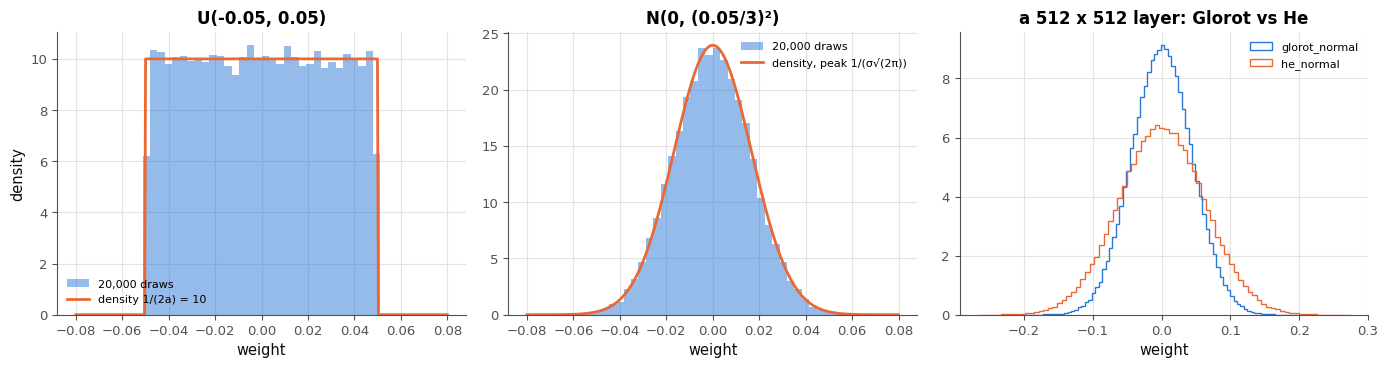

In [31]:
def draw_15(rng):
    """Draw three panels with matplotlib (do not call plt.show()):
    (1) the histogram (density=True) of 20,000 draws of U(-0.05, 0.05) and its true density;
    (2) the same for N(0, (0.05/3)**2), the normal law of figure 16.6;
    (3) the histograms of the weights of a 512 x 512 layer initialised with "glorot_normal" and "he_normal".
    Use mylearn.nn.layers.init_weights for every draw, with the generator rng. Return the figure."""
    sigma = 0.05 / 3
    uniform = mylearn.nn.layers.init_weights(200, 100, "uniform", rng, scale=0.05).ravel()
    normal = mylearn.nn.layers.init_weights(200, 100, "normal", rng, scale=sigma).ravel()
    grid = np.linspace(-0.08, 0.08, 400)
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
    axes[0].hist(uniform, bins=50, range=(-0.08, 0.08), density=True, alpha=0.5, label="20,000 draws")
    axes[0].plot(grid, np.where(np.abs(grid) <= 0.05, 1 / 0.1, 0.0), lw=2, label="density 1/(2a) = 10")
    axes[1].hist(normal, bins=50, range=(-0.08, 0.08), density=True, alpha=0.5, label="20,000 draws")
    axes[1].plot(grid, np.exp(-grid ** 2 / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi)), lw=2,
                 label="density, peak 1/(σ√(2π))")
    for method in ["glorot_normal", "he_normal"]:
        axes[2].hist(mylearn.nn.layers.init_weights(512, 512, method, rng).ravel(), bins=80, density=True,
                     histtype="step", lw=1.5, label=method)
    axes[0].set_title("U(-0.05, 0.05)")
    axes[1].set_title("N(0, (0.05/3)²)")
    axes[2].set_title("a 512 x 512 layer: Glorot vs He")
    for ax in axes:
        ax.set_xlabel("weight")
        ax.legend(fontsize=8)
    axes[0].set_ylabel("density")
    fig.tight_layout()
    return fig


height_15 = 1 / (2 * 0.05)
peak_15 = 1 / ((0.05 / 3) * np.sqrt(2 * np.pi))
ratio_15 = np.sqrt(2 / 512) / np.sqrt(2 / (512 + 512))     # = sqrt(2) for any square layer
print_answer("16.15a", height_15)
print_answer("16.15b", peak_15)
print_answer("16.15c", ratio_15)
if True:
    figure_15 = draw_15(np.random.default_rng(1615))
    if returned("16.15", "draw_15", figure_15):
        plt.show()

In [32]:
wb.record("16.15a", height_15, decimals=2,
          mistakes={"la hauteur h d'une densité uniforme sur un intervalle de longueur 2a vérifie h × 2a = 1": 20,
                    "c'est la largeur de l'intervalle : la hauteur est son inverse": 0.1})
wb.record("16.15b", peak_15, decimals=1,
          mistakes={"le pic vaut 1/(σ√(2π)) avec σ = 0,05/3, pas σ = 0,05": 1 / (0.05 * np.sqrt(2 * np.pi)),
                    "1/(σ√(2π)) : as-tu oublié la racine de 2π ?": 1 / (0.05 / 3), "le pic d'une densité n'est pas une probabilité : il peut dépasser 1": 1})
wb.record("16.15c", ratio_15, decimals=3,
          mistakes={"c'est le rapport des VARIANCES : on demande celui des écarts-types": 2, "He a la plus grande variance : le rapport dépasse 1": 1 / np.sqrt(2),
                    "pour une couche carrée, Glorot vaut 2/(2n) = 1/n : ce n'est pas la même règle que He": 1})

WB_ANSWER {"decimals": 2, "hash": "423033d2556fffae3e23fed1f86574b78b062667049c67ac8976be9d68f7fc59", "hash_coarse": "f38bbbfb4a2741214d2025ccdfcf2210d5ce2bc2aedbec365de86f0af96a658b", "id": "16.15a", "kind": "float", "magnitude": 1, "mistakes": {"1882cbf26430ce1efde1e639cbca58b1ce4c01197affcd50016bd7c1c0a6a880": "c'est la largeur de l'intervalle : la hauteur est son inverse", "4e5fa82946acee1053adf54f04fcb03e673c40f8ab589677dc83d666dd0e3b47": "la hauteur h d'une densité uniforme sur un intervalle de longueur 2a vérifie h × 2a = 1"}, "sign": 1}
📝 Ex 16.15a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 1, "hash": "e854fd27dd54ab90eb1110cf184760e97365def3ca20315aedc21e787da0baf5", "hash_coarse": "6715f94e37b68ee44feabbdfd3b93e3250bbbad1fd1e24f3e68f13b35de851d9", "id": "16.15b", "kind": "float", "magnitude": 1, "mistakes": {"35f3bb2a32faa23210c00a8e5627ead5ba4f1a87f0b53d862720758954955e39": "1/(σ√(2π)) : as-tu oublié la racine de 2π ?", "a8c63d892b8d5298a0169f6d594e

💡 La densité uniforme vaut $1/(2a) = 10$ sur l'intervalle : son aire, $10 \times 0{,}1$, fait 1. Le pic de la loi normale vaut $1/(\sigma\sqrt{2\pi}) \approx 23{,}9$ : des hauteurs bien au-dessus de 1, preuve que ce ne sont pas des probabilités. La probabilité de dépasser 0,05, soit trois écarts-types, vaut environ 0,27 % : « presque nulle », mais pas nulle, et une loi normale n'a pas de bornes. Pour une couche carrée, Glorot donne $\mathrm{Var}(w) = 2/(2n) = 1/n$, comme LeCun, et He $2/n$ : l'écart-type de He est $\sqrt{2} \approx 1{,}414$ fois plus grand, et son histogramme plus large. C'est He qui convient à une couche ReLU, qui met à zéro la moitié des valeurs.

### Ex 16.16 — Ordre topologique d'un graphe : topological_order 🔨 ★★ ⏱️ 25 min
**Objectif :** écrire l'algorithme de Kahn, avec une règle déterministe parmi les nœuds prêts et la détection des cycles.  
**Prérequis :** ✏️ 16.4 · fiche §16.2 (encadré sur l'ordre topologique) · **mylearn :** `nn/layers.py` · **Parcours :** C

> **mylearn** : dans `mon_travail/mylearn/nn/layers.py`, mêmes règles qu'en 16.12. Enregistre, puis relance la cellule de vérification.

Écris `topological_order`. **Contrat** (la docstring, plus ces précisions que vérifient les tests) : `topological_order(graph)` reçoit un dictionnaire `{parent: [enfants, ...]}` (des noms en chaînes de caractères) et rend la **liste** de tous les nœuds, chacun une fois : ceux qui ne sont que des enfants (sans clé) et ceux qui n'ont ni parent ni enfant (une clé de liste vide) compris. Chaque parent vient avant tous ses enfants ; parmi les nœuds prêts (tous leurs parents déjà rangés), on range toujours le **plus petit** dans l'ordre alphabétique, si bien que l'ordre est unique (ce n'est donc pas un parcours couche par couche). `ValueError` si le graphe a un cycle, une arête d'un nœud vers lui-même comprise. La fonction ne modifie pas le dictionnaire reçu.

La vérification essaie les exemples de la docstring, contrôle sur 30 graphes au hasard que chaque nœud vient après ses parents, vérifie la détection d'un cycle, puis lance les tests (dont une comparaison avec `graphlib` de la bibliothèque standard).

Dans tes notes : combien d'opérations ton algorithme fait-il pour un graphe de $V$ nœuds et $E$ arêtes ? À quoi servira un ordre topologique au ch. 18, et dans quel sens le parcourra-t-on ?

In [33]:
if True:
    print("docstring examples:", mylearn.nn.layers.topological_order({"x": ["h1", "h2"], "h1": ["y"], "h2": ["y"]}),
          "and", mylearn.nn.layers.topological_order({"b": ["c"], "a": ["c"]}),
          "(expected ['x', 'h1', 'h2', 'y'] and ['a', 'b', 'c'])")
if True:
    rng_16 = np.random.default_rng(1616)
    respected_16 = True
    for trial_16 in range(30):                       # random DAGs: an edge only from a smaller to a larger index
        names_16 = [f"n{k:02d}" for k in rng_16.permutation(12)]
        graph_16 = {names_16[i]: [names_16[j] for j in range(i + 1, 12) if rng_16.random() < 0.25] for i in range(12)}
        order_16 = mylearn.nn.layers.topological_order(graph_16)
        position_16 = {node: k for k, node in enumerate(order_16)}
        respected_16 = respected_16 and sorted(order_16) == sorted(names_16) and all(
            position_16[parent] < position_16[child] for parent, children in graph_16.items() for child in children)
    verdict("16.16", respected_16, "sur 30 graphes au hasard, chaque nœud apparaît une fois, après tous ses parents (comme l'exige graphlib).",
            "sur un graphe au hasard, un nœud manque, apparaît deux fois ou vient avant l'un de ses parents.")
    cycle_16 = {"a": ["b"], "b": ["c"], "c": ["a"], "d": ["a"]}
    try:
        mylearn.nn.layers.topological_order(cycle_16)
        print("❌ Ex 16.16 : le graphe a → b → c → a a un cycle : ta fonction doit lever une ValueError.")
    except ValueError:
        print("✅ Ex 16.16 : un graphe avec un cycle lève une ValueError, comme graphlib lève une CycleError.")
if written(lambda: mylearn.nn.layers.topological_order({"a": ["b"]})):
    run_mylearn_tests(impl="ref", module="layers", keyword="test_topological_order_")
else:
    print("⏳ Ex 16.16 : les tests attendent ton topological_order.")

docstring examples: ['x', 'h1', 'h2', 'y'] and ['a', 'b', 'c'] (expected ['x', 'h1', 'h2', 'y'] and ['a', 'b', 'c'])
✅ Ex 16.16 : sur 30 graphes au hasard, chaque nœud apparaît une fois, après tous ses parents (comme l'exige graphlib).
✅ Ex 16.16 : un graphe avec un cycle lève une ValueError, comme graphlib lève une CycleError.


pytest: 11 passed, 109 deselected in 0.97s


💡 Kahn compte les parents en parcourant chaque arête une fois, puis range chaque nœud une fois et décrémente les comptes de ses enfants : $O(V + E)$ opérations, plus $O(\log V)$ par nœud pour le tas qui garde les nœuds prêts triés (`heapq`). Au ch. 18, la rétropropagation parcourt un graphe de calcul dans l'ordre topologique **inverse** : un nœud ne transmet son gradient à ses parents qu'une fois reçus ceux de tous ses enfants.

## Partie C · Empiler les couches

Ton `init_mlp` et ton `mlp_forward` (16.17), les poids d'un `MLPClassifier` de scikit-learn relus par ta passe avant (16.18), des neurones jumeaux (16.19), une passe avant buggée (16.20), puis des tests de reproductibilité (16.21).

### Ex 16.17 — Empiler les couches : init_mlp et mlp_forward 🔨 ★★ ⏱️ 30 min
**Objectif :** initialiser un MLP couche par couche, puis écrire sa passe avant avec le cache que demandera la rétropropagation.  
**Prérequis :** Ex 16.13 · Ex 16.14 · fiche, section sur la passe avant (empiler les couches, encadré sur la non-linéarité) · **Fil rouge :** MNIST · **mylearn :** `nn/layers.py` · **Parcours :** R, M, C

> **mylearn** : dans `mon_travail/mylearn/nn/layers.py`, mêmes règles qu'en 16.12. Enregistre, puis relance la cellule de vérification.

Écris `init_mlp` et `mlp_forward`. **Contrat** (les docstrings, plus ces précisions que vérifient les tests) :
- `init_mlp(layer_sizes, method="he_normal", rng=None)` rend une **liste** de couples `(W, b)`, un par couche : `W = init_weights(n_(l-1), n_l, method, rng)` et `b = np.zeros(n_l)` ; **un seul** générateur (`np.random.default_rng(rng)`) sert à toutes les couches, tirées dans l'ordre (la première d'abord), si bien que deux couches de même forme ont des poids différents ; `ValueError` comme `count_parameters` et `init_weights` ;
- `mlp_forward(x, params, activation=None, output_activation=None, return_cache=False)` applique les couches dans l'ordre : `z = dense_forward(a, W, b)`, puis `activation(z)` pour une couche cachée et `output_activation(z)` pour la dernière (`None` : l'identité ; la sortie est alors faite des logits) ; avec `return_cache=True`, elle rend le couple `(out, cache)`, où `cache` est une liste d'un couple `(a_prev, z)` par couche, `a_prev` étant l'entrée de la couche (`x` pour la première) et `z` sa somme pondérée **avant** l'activation ; `ValueError` si `params` est vide, ou si les formes ne s'enchaînent pas (comme `dense_forward`). Elle ne modifie ni `x` ni les paramètres.

La vérification essaie les exemples des docstrings, initialise un MLP 784-128-64-10 en Glorot normale, compare ses logits sur 256 images à ceux d'un `torch.nn.Sequential` qui a reçu les mêmes poids, affiche l'écart-type de `z` couche par couche, puis lance les tests.

Dans tes notes : pourquoi le cache garde-t-il `z` et pas seulement l'activation ? Quelle est la forme de `W` dans `cache` et dans PyTorch, et pourquoi la cellule transpose-t-elle avant de copier ?

In [34]:
if True:
    params_doc_17 = mylearn.nn.layers.init_mlp([2, 4, 4, 1], rng=np.random.default_rng(0))
    print("docstring example (init_mlp): shapes", [np.shape(W) for W, b in params_doc_17], "(expected [(2, 4), (4, 4), (4, 1)])",
          "· size", sum(np.size(W) + np.size(b) for W, b in params_doc_17), "(expected 37)")
if True:
    params_ex_17 = [(np.array([[1.0, -1.0], [0.5, -2.0]]), np.array([0.0, 1.0])), (np.array([[1.0], [1.0]]), np.array([-1.0]))]
    out_ex_17, cache_ex_17 = mylearn.nn.layers.mlp_forward(np.array([[1.0, 1.0]]), params_ex_17, activation=relu, return_cache=True)
    print("docstring example (mlp_forward):", np.asarray(out_ex_17).tolist(), "(expected [[0.5]]) · cache z of the hidden layer",
          np.asarray(cache_ex_17[0][1]).tolist(), "(expected [[1.5, -2.0]])")
if True:
    sizes_17 = [784, 128, 64, 10]
    params_17 = mylearn.nn.layers.init_mlp(sizes_17, "glorot_normal", rng=np.random.default_rng(1617))
    X_17 = X_STD[:256]
    logits_17, cache_17 = mylearn.nn.layers.mlp_forward(X_17, params_17, activation=np.tanh, return_cache=True)
    verdict("16.17", np.shape(logits_17) == (256, 10) and len(cache_17) == 3
            and [np.shape(a) for a, _ in cache_17] == [(256, 784), (256, 128), (256, 64)]
            and [np.shape(z) for _, z in cache_17] == [(256, 128), (256, 64), (256, 10)],
            "784-128-64-10 sur 256 images : des logits (256, 10) et un cache de 3 couples (a_prev, z) aux bonnes formes.",
            "attendu : des logits (256, 10) et un cache de 3 couples (a_prev, z), a_prev de formes (256, 784), (256, 128), "
            "(256, 64) et z de formes (256, 128), (256, 64), (256, 10).")
    if torch is not None:
        model_17 = torch.nn.Sequential(torch.nn.Linear(784, 128), torch.nn.Tanh(), torch.nn.Linear(128, 64), torch.nn.Tanh(),
                                       torch.nn.Linear(64, 10)).double()
        with torch.no_grad():
            for layer_17, (W_17, b_17) in zip(model_17[::2], params_17):
                layer_17.weight.copy_(torch.tensor(np.asarray(W_17).T))   # PyTorch stores (n_out, n_in)
                layer_17.bias.copy_(torch.tensor(np.asarray(b_17)))
            oracle_17 = model_17(torch.tensor(X_17)).numpy()
        verdict("16.17", np.shape(logits_17) == oracle_17.shape and np.allclose(logits_17, oracle_17),
                "mêmes logits qu'un torch.nn.Sequential de Linear et de Tanh qui a reçu tes poids (transposés).",
                "tes logits diffèrent de ceux de PyTorch avec les mêmes poids : l'activation est-elle appliquée aux couches "
                "cachées seulement, et z est-il gardé AVANT l'activation ?")
    stds_17 = [float(np.std(z)) for _, z in cache_17]
    print("std of z, layer by layer:", np.round(stds_17, 3).tolist())
if written(lambda: mylearn.nn.layers.init_mlp([1, 1])) or written(lambda: mylearn.nn.layers.mlp_forward(np.ones((1, 1)), [(np.ones((1, 1)), np.zeros(1))])):
    run_mylearn_tests(impl="ref", module="layers", keyword="test_init_mlp_ or test_mlp_forward_")
else:
    print("⏳ Ex 16.17 : les tests attendent ton init_mlp et ton mlp_forward.")

docstring example (init_mlp): shapes [(2, 4), (4, 4), (4, 1)] (expected [(2, 4), (4, 4), (4, 1)]) · size 37 (expected 37)
docstring example (mlp_forward): [[0.5]] (expected [[0.5]]) · cache z of the hidden layer [[1.5, -2.0]] (expected [[1.5, -2.0]])
✅ Ex 16.17 : 784-128-64-10 sur 256 images : des logits (256, 10) et un cache de 3 couples (a_prev, z) aux bonnes formes.
✅ Ex 16.17 : mêmes logits qu'un torch.nn.Sequential de Linear et de Tanh qui a reçu tes poids (transposés).
std of z, layer by layer: [1.288, 0.796, 0.704]


pytest: 23 passed, 97 deselected in 1.94s


💡 La passe arrière du ch. 18 aura besoin, pour chaque couche, de la dérivée de l'activation **en $z$** (par exemple $1 - \tanh^2(z)$, ou 1 si $z > 0$ pour ReLU) et de l'entrée `a_prev` (le gradient d'un poids $W_{jk}$ fait intervenir l'entrée $j$) : le cache garde exactement ces deux tableaux. `nn.Linear` range ses poids en `(n_out, n_in)` : copier `W` sans le transposer lèverait une erreur ici, mais pas pour une couche carrée.

### Ex 16.18 — Relire un MLPClassifier de scikit-learn avec ton mlp_forward 📦 ★★ ⏱️ 25 min
**Objectif :** retrouver les prédictions d'un réseau de scikit-learn à partir de ses poids, avec ta propre passe avant.  
**Prérequis :** Ex 16.17 · ch. 15 (attributs appris) · fiche, encadré sur les poids d'un MLPClassifier · **Fil rouge :** MNIST · **Parcours :** C

La cellule fournie entraîne un `MLPClassifier(hidden_layer_sizes=(64,))` (une couche cachée de 64 neurones ReLU) pendant 30 epochs sur 6 000 images MNIST, dont les pixels sont divisés par 255, et définit `softmax_18`, une softmax de chaque ligne. Ses poids sont dans `coefs_` et `intercepts_`, au format de ta librairie.

Calcule :
a) `n_params_18` : le nombre de paramètres du réseau, compté à partir de `coefs_` et `intercepts_` ;
b) `shape_18` : la forme de `coefs_[0]`, entre guillemets ;
puis range ses paramètres dans `params_18`, une liste de couples `(W, b)`, et calcule avec **ton** `mlp_forward` les probabilités `proba_18` des 2 000 images de test (ReLU dans la couche cachée, `softmax_18` à la sortie) :
c) `agree_18` : la part des images de test où l'argmax de `proba_18` est la classe prédite par `CLF_18.predict` ;
d) `gap_18` : le plus grand écart absolu entre `proba_18` et `CLF_18.predict_proba` ;
e) `accuracy_18` : l'accuracy de test de tes prédictions (l'argmax de `proba_18`) ;
f) `tanh_agree_18` : la part de c) si ta passe avant utilise `np.tanh` au lieu de ReLU, avec les mêmes poids.

Dans tes notes : que t'apprend f) sur ce qu'il faut savoir d'un réseau, en plus de ses poids, pour refaire ses prédictions ? Pourquoi une softmax n'est-elle pas nécessaire pour retrouver `predict` ?

In [35]:
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPClassifier

X_TRAIN_18, Y_TRAIN_18 = wb.datasets.load_mnist("train", n=6000, flatten=True, normalize=True, seed=1618)
X_TEST_18, Y_TEST_18 = wb.datasets.load_mnist("test", n=2000, flatten=True, normalize=True, seed=1618)
X_TRAIN_18, X_TEST_18 = X_TRAIN_18.astype(float), X_TEST_18.astype(float)   # pixels / 255, in float64
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)                       # 30 epochs only, on purpose
    CLF_18 = MLPClassifier(hidden_layer_sizes=(64,), max_iter=30, random_state=0).fit(X_TRAIN_18, Y_TRAIN_18)
print(f"MLPClassifier: {CLF_18.n_iter_} epochs, test accuracy {CLF_18.score(X_TEST_18, Y_TEST_18):.3f}")


def softmax_18(z):
    """Softmax of each row (stable: the largest value of the row is subtracted first)."""
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

MLPClassifier: 30 epochs, test accuracy 0.939


In [36]:
n_params_18 = sum(W.size + b.size for W, b in zip(CLF_18.coefs_, CLF_18.intercepts_))
shape_18 = str(CLF_18.coefs_[0].shape)
params_18 = list(zip(CLF_18.coefs_, CLF_18.intercepts_))
proba_18 = mylearn.nn.layers.mlp_forward(X_TEST_18, params_18, activation=relu, output_activation=softmax_18)
agree_18 = float(np.mean(proba_18.argmax(axis=1) == CLF_18.predict(X_TEST_18)))
gap_18 = float(np.abs(proba_18 - CLF_18.predict_proba(X_TEST_18)).max())
accuracy_18 = float(np.mean(proba_18.argmax(axis=1) == Y_TEST_18))
tanh_proba_18 = mylearn.nn.layers.mlp_forward(X_TEST_18, params_18, activation=np.tanh, output_activation=softmax_18)
tanh_agree_18 = float(np.mean(tanh_proba_18.argmax(axis=1) == CLF_18.predict(X_TEST_18)))
print_answer("16.18a", n_params_18)
print_answer("16.18b", shape_18)
if True:
    print_answer("16.18c", agree_18, computed=True)
    print_answer("16.18d", gap_18, computed=True)
    print_answer("16.18e", accuracy_18, computed=True)
    print_answer("16.18f", tanh_agree_18, computed=True)

16.18a: 50890
16.18b: (784, 64)
16.18c: 1.0
16.18d: 0.0
16.18e: 0.939
16.18f: 0.7685


In [37]:
wb.record("16.18a", n_params_18,
          mistakes={"as-tu compté les biais (intercepts_) ?": int(sum(W.size for W in CLF_18.coefs_)),
                    "as-tu compté la couche de sortie ?": int(CLF_18.coefs_[0].size + CLF_18.intercepts_[0].size)})
wb.record("16.18b", shape_18, mistakes={"scikit-learn range les poids en (n_in, n_out), comme ta librairie": "(64, 784)"})
wb.record("16.18c", agree_18, decimals=4,
          mistakes={"as-tu utilisé ReLU dans la couche cachée, comme MLPClassifier par défaut ?": tanh_agree_18})
wb.record("16.18d", gap_18, decimals=4)
wb.record("16.18e", accuracy_18, decimals=4,
          mistakes={"c'est l'accord avec CLF_18.predict ; on demande l'accuracy face aux vrais labels Y_TEST_18": agree_18})
wb.record("16.18f", tanh_agree_18, decimals=2,
          mistakes={"relis la question : avec np.tanh au lieu de ReLU, les prédictions changent-elles ?": agree_18})

WB_ANSWER {"hash": "067a1a83aebfbee5b45bbb18971326b0e813c6c3685df94a99fbf7254da98c22", "id": "16.18a", "kind": "int", "magnitude": 4, "mistakes": {"086c673715101f4e26c44af7e89453eb2129a269eb93e18f73da90e09fe495b0": "as-tu compté les biais (intercepts_) ?", "ba54fc6cb44f9af6583443ebb02c90e2437c674bee1353dfe10f8aa69eb36834": "as-tu compté la couche de sortie ?"}, "sign": 1}
📝 Ex 16.18a : réponse enregistrée (int).
WB_ANSWER {"hash": "b35c93b4cf0a020347601c9d70b50b80135ebb06d78f15cf3a67e89e8cab1e20", "id": "16.18b", "kind": "str", "mistakes": {"84f1788509725e74dbbd20a67a4dee40b0da866a1a28333ab962f5bf760fa821": "scikit-learn range les poids en (n_in, n_out), comme ta librairie"}}
📝 Ex 16.18b : réponse enregistrée (str).
WB_ANSWER {"decimals": 4, "hash": "a7901f22387429d4a09c6b4f104cb6c4c5b1da4eff5cbe4260b6896cc0099052", "hash_coarse": "c4cdd25386ae5c53cf6bec700ba609501a564c34a870282e02c98aa05db0b0c1", "id": "16.18c", "kind": "float", "magnitude": 0, "mistakes": {"3932e79da0535db7fdcb233e57

💡 Le réseau a $784 \times 64 + 64 + 64 \times 10 + 10 = 50\,890$ paramètres, et `coefs_[0]` la forme `(784, 64)` : la convention de ta librairie. Avec ReLU et la softmax, ta passe avant retrouve **toutes** les prédictions et les probabilités de scikit-learn, à l'arrondi près (ici, un écart nul) : accuracy de test 0,939. Avec tanh et les **mêmes** poids, à peine plus de trois prédictions sur quatre restent les mêmes (0,77) : les poids seuls ne suffisent pas, il faut l'architecture complète, activations comprises (c'est pourquoi on sauvegarde un modèle avec son code ou sa configuration). La softmax garde l'ordre des logits (elle est croissante) : l'argmax des logits suffit à retrouver `predict`.

### Ex 16.19 — Initialisation constante : les neurones restent-ils jumeaux ? 🔮 ★★ ⏱️ 20 min
**Objectif :** prévoir, avant de le voir, ce que devient une couche initialisée par une constante pendant l'entraînement.  
**Prérequis :** Ex 16.17 · ∂ 16.6 · ch. 5 (gradient numérique, descente de gradient) · fiche §16.4.1 · **Fil rouge :** synth · **Parcours :** M, C

Un réseau 2-4-1 (tanh dans la couche cachée, pas d'activation à la sortie) apprend un « ou exclusif » de 200 points (`X_19`, labels 0 et 1), en minimisant la MSE par 200 pas de descente de gradient (learning rate 0,5). Le gradient est calculé par **différences finies** (ch. 5, `numerical_gradient_19`), en appelant ta `mlp_forward` : aucune formule de rétropropagation, rien qui puisse traiter deux neurones différemment. `spread_19` mesure l'écart entre les quatre neurones cachés (le plus grand écart entre les poids entrants, le biais et le poids sortant d'un neurone et ceux du neurone 0). Trois départs : tous les paramètres à 0,5 ; une initialisation de Glorot normale ; tous à 0,5, plus un bruit d'écart-type $10^{-4}$ sur les poids entrants.

Prédis, **avant** d'exécuter quoi que ce soit :
a) `twins_19` : après 200 pas, les quatre neurones partis de 0,5 sont-ils encore identiques (`spread_19` exactement nul) ? `True` ou `False` ;
b) `loss_19_choice` : la MSE finale du départ constant, comparée à celle du départ de Glorot : `"A"` moins de la moitié ; `"B"` entre la moitié et le double ; `"C"` plus du double ;
c) `noise_19` : après 200 pas, le départ constant bruité : `"A"` les neurones sont encore jumeaux à $10^{-3}$ près ; `"B"` ils se sont séparés, mais la MSE reste proche de celle du départ constant ; `"C"` ils se sont séparés, et la MSE est proche de celle du départ de Glorot.

Puis exécute l'expérience : elle entraîne les trois départs, affiche leurs MSE et leurs écarts avant et après, et vérifie tes prédictions.

In [38]:
X_19, Y_19 = wb.synth.make_xor(n=200, noise=0.15, seed=1619)   # two classes in "exclusive or", labels 0 and 1
Y_19 = Y_19.astype(float)


def loss_19(params):
    """Mean squared error of a 2-4-1 network with tanh in the hidden layer (YOUR mlp_forward), on the 200 points."""
    out = mylearn.nn.layers.mlp_forward(X_19, params, activation=np.tanh)
    return float(np.mean((np.asarray(out)[:, 0] - Y_19) ** 2))


def numerical_gradient_19(params, h=1e-6):
    """Central differences (chapter 5): the derivative of loss_19 with respect to every weight and every bias."""
    grads = []
    for W, b in params:
        gradient = []
        for array in (W, b):
            g = np.zeros_like(array)
            for index in np.ndindex(array.shape):
                old = array[index]
                array[index] = old + h
                up = loss_19(params)
                array[index] = old - h
                down = loss_19(params)
                array[index] = old
                g[index] = (up - down) / (2 * h)
            gradient.append(g)
        grads.append(tuple(gradient))
    return grads


def train_19(params, steps=200, lr=0.5):
    """`steps` steps of gradient descent on a COPY of params; return the trained copy."""
    params = [(np.array(W, dtype=float), np.array(b, dtype=float)) for W, b in params]
    for _ in range(steps):
        for (W, b), (gW, gb) in zip(params, numerical_gradient_19(params)):
            W -= lr * gW
            b -= lr * gb
    return params


def spread_19(params):
    """How different the 4 hidden neurons are: the largest gap between the incoming weights, bias and outgoing weight
    of a neuron and those of neuron 0."""
    (W1, b1), (W2, _) = params
    neurons = np.vstack([W1, b1[None, :], W2.T])            # one column per hidden neuron
    return float(np.abs(neurons - neurons[:, :1]).max())


def constant_19(c):
    """Every weight and every bias equal to c."""
    return [(np.full((2, 4), c), np.full(4, c)), (np.full((4, 1), c), np.full(1, c))]

In [39]:
twins_19, loss_19_choice, noise_19 = True, "C", "B"   # the answers, for the record

In [40]:
wb.record("16.19a", True, mistakes={"relis ∂ 16.6 : deux neurones jumeaux reçoivent-ils des gradients différents, même calculés par différences finies ?": False})
wb.record("16.19b", "C", mistakes={"un réseau aux neurones jumeaux équivaut à un réseau à UN neurone caché : peut-il séparer un « ou exclusif » ?": "A",
                                   "quatre neurones jumeaux ne valent qu'un neurone caché : un « ou exclusif » demande au moins deux frontières": "B"})
wb.record("16.19c", "B", mistakes={"un départ presque symétrique n'est pas symétrique : les petits écarts grandissent-ils pendant l'entraînement ?": "A",
                                   "les neurones se séparent, mais partis de 10⁻⁴, combien de pas leur faut-il pour devenir assez différents ?": "C"})

WB_ANSWER {"hash": "93e6b68f0a0cae70b3fedd83dd1c6cc31db32d4f2f518569e3773ee8833962a2", "id": "16.19a", "kind": "bool", "mistakes": {"5773cf2133a7d3f482bc8df5ec7f676968756b77f44c11f20f0c04f2bb0f169d": "relis ∂ 16.6 : deux neurones jumeaux reçoivent-ils des gradients différents, même calculés par différences finies ?"}}
📝 Ex 16.19a : réponse enregistrée (bool).
WB_ANSWER {"hash": "c7da2c9917c4b080484727678ac5d35f893ac23da02ebcee3ef6622ea3265751", "id": "16.19b", "kind": "str", "mistakes": {"1fa3cff4ee85e58274ddd0e9072dfef8a08c73486c91df8e90a5a318a8c7eeed": "quatre neurones jumeaux ne valent qu'un neurone caché : un « ou exclusif » demande au moins deux frontières", "8134eec7b7eea690204b3b71326950e322e4a48c492e34d4e558d7255751555d": "un réseau aux neurones jumeaux équivaut à un réseau à UN neurone caché : peut-il séparer un « ou exclusif » ?"}}
📝 Ex 16.19b : réponse enregistrée (str).
WB_ANSWER {"hash": "122cd42b51010d02744129dc0cfee751427bd56bc76a924b78191354dd235422", "id": "16.19c", "k

In [41]:
if any(answer is ... or answer is None for answer in [twins_19, loss_19_choice, noise_19]):
    print("⏳ Ex 16.19 : écris d'abord tes trois prédictions, puis relance cette cellule.")
else:
    with wb.attempt("16.19"):
        rng_19 = np.random.default_rng(1619)
        starts_19 = {"constant 0.5": constant_19(0.5),
                     "random (glorot_normal)": mylearn.nn.layers.init_mlp([2, 4, 1], "glorot_normal", rng_19),
                     "constant 0.5 + noise 1e-4": [(constant_19(0.5)[0][0] + 1e-4 * rng_19.normal(size=(2, 4)), np.full(4, 0.5)),
                                                   (np.full((4, 1), 0.5), np.full(1, 0.5))]}
        results_19 = {}
        for name_19, start_19 in starts_19.items():
            trained_19 = train_19(start_19)
            results_19[name_19] = (loss_19(start_19), loss_19(trained_19), spread_19(start_19), spread_19(trained_19))
            print(f"{name_19:27} loss {results_19[name_19][0]:.4f} -> {results_19[name_19][1]:.4f} · "
                  f"spread of the neurons {results_19[name_19][2]:.2e} -> {results_19[name_19][3]:.2e}")
        wb.check("16.19a", twins_19)
        wb.check("16.19b", loss_19_choice)
        wb.check("16.19c", noise_19)

constant 0.5                loss 2.0761 -> 0.2443 · spread of the neurons 0.00e+00 -> 0.00e+00


random (glorot_normal)      loss 1.2124 -> 0.0191 · spread of the neurons 1.48e+00 -> 2.88e+00


constant 0.5 + noise 1e-4   loss 2.0761 -> 0.2334 · spread of the neurons 2.13e-04 -> 3.34e-01
✅ Ex 16.19a : Bien joué !
✅ Ex 16.19b : C'est ça !
✅ Ex 16.19c : Parfait !


Dans tes notes : relie a) à la preuve ∂ 16.6. Un réseau dont les quatre neurones cachés sont jumeaux équivaut à un réseau à combien de neurones cachés, et peut-il apprendre un « ou exclusif » ? En c), d'où vient la séparation des neurones, et que faudrait-il pour que le réseau apprenne vraiment ?

💡 a) Les quatre neurones partis de 0,5 restent **exactement** jumeaux (écart nul), même avec un gradient calculé par différences finies : par symétrie, chaque neurone reçoit la même correction (∂ 16.6). Le réseau ne vaut alors qu'un neurone caché, incapable de séparer un « ou exclusif » : sa MSE finale (0,244) reste proche de celle d'une prédiction constante (0,25), environ 13 fois celle du départ de Glorot (0,019). c) Un bruit de $10^{-4}$ brise la symétrie, et les écarts **grandissent** pendant l'entraînement (de 0,0002 à 0,33) : le point symétrique est instable. Mais 200 pas ne suffisent pas pour que les neurones deviennent assez différents, et la MSE reste proche de celle du départ constant (0,233). Il faut des poids **vraiment** différents dès le départ, à l'échelle d'une règle d'initialisation.

### Ex 16.20 — Chasse au bug : transposée, biais mal diffusé, variance prise pour un écart-type 🐛 ★★ ⏱️ 25 min
**Objectif :** trouver trois erreurs qu'aucun message ne signale dans une initialisation et une passe avant écrites à la main.  
**Prérequis :** Ex 16.17 · 🔮 16.11 · fiche, section sur la passe avant (encadré sur le biais et la transposée), §16.4.1 · **Parcours :** C

Un collègue a écrit `init_20`, une initialisation de He normale, et `forward_20`, une passe avant ReLU. Il les a essayées sur un réseau 64-64-64-64 et un batch de 64 images : tout s'exécute sans erreur. Il y a pourtant **trois** erreurs : trouve-les et corrige-les, sans changer les signatures ni la convention du chapitre (`W` de forme `(n_in, n_out)`, un exemple par ligne).

La vérification contrôle trois propriétés, dans l'ordre (un point ne se teste que si les précédents passent) : 1) les poids d'une couche de 256 entrées ont l'écart-type de He ; 2) chaque image donne la même sortie seule ou dans le batch ; 3) la passe avant marche sur un réseau aux couches non carrées et donne le résultat d'une boucle sur les neurones. Elle affiche ensuite l'écart-type des sommes pondérées à travers 10 couches initialisées par `init_20`. Cet exercice se corrige avec `05_solutions.md`.

Dans tes notes : pour chaque erreur, pourquoi le réseau carré et le batch de 64 images la cachaient-ils ? Quel symptôme chacune, seule, aurait-elle sur un réseau profond ?

In [42]:
def init_20(layer_sizes, rng):
    """He normal initialisation: a list of (W, b), W of shape (n_in, n_out), b of zeros."""
    params = []
    for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
        W = rng.normal(0.0, np.sqrt(2 / n_in), size=(n_in, n_out))      # fix 1: normal() takes a STANDARD DEVIATION
        params.append((W, np.zeros(n_out)))
    return params


def forward_20(x, params):
    """Forward pass with ReLU on the hidden layers and no activation at the output."""
    a = np.asarray(x, dtype=float)
    for k, (W, b) in enumerate(params):
        z = a @ W + b                    # fix 2: a bias of shape (n_out,) per neuron; fix 3: W is (n_in, n_out), no .T
        a = z if k == len(params) - 1 else np.maximum(0.0, z)
    return a
if True:
    rng_20 = np.random.default_rng(1620)
    params_20 = init_20([64, 64, 64, 64], rng_20)
    W_test_20 = np.asarray(init_20([256, 256], np.random.default_rng(0))[0][0])
    X_20 = X_STD[:64, :64]                                     # 64 images, 64 pixels: a square batch, on purpose
    trial_params_20 = [(np.asarray(W) + 0.0, np.random.default_rng(k).normal(size=np.shape(b))) for k, (W, b) in enumerate(params_20)]
    batch_20 = np.asarray(forward_20(X_20, trial_params_20))
    alone_20 = [np.asarray(forward_20(X_20[i:i + 1], trial_params_20)) for i in range(5)]
    small_20 = [(np.random.default_rng(3).normal(size=(64, 32)), np.random.default_rng(4).normal(size=32)),
                (np.random.default_rng(5).normal(size=(32, 10)), np.random.default_rng(6).normal(size=10))]
    try:
        rect_20 = np.asarray(forward_20(X_20, small_20))
    except ValueError:
        rect_20 = None
    loop_20 = X_20.copy()
    for k_20, (W_20, b_20) in enumerate(small_20):             # the same network, one neuron at a time
        loop_20 = np.array([[sum(row[j] * W_20[j, n] for j in range(W_20.shape[0])) + b_20[n] for n in range(W_20.shape[1])]
                            for row in loop_20])
        loop_20 = loop_20 if k_20 == len(small_20) - 1 else np.maximum(0.0, loop_20)
    diagnostics_20 = [
        ("les poids d'une couche de 256 entrées ont l'écart-type de He, √(2/256) ≈ 0,088 (à 5 % près)",
         abs(float(W_test_20.std()) / np.sqrt(2 / 256) - 1) < 0.05),
        ("chaque image donne la même sortie seule ou dans le batch (forme (1, 64) et mêmes valeurs)",
         all(a.shape == (1, 64) and np.allclose(a[0], batch_20[i]) for i, a in enumerate(alone_20))),
        ("la passe avant marche sur un réseau aux couches non carrées (64-32-10) et donne le résultat d'une boucle sur les neurones",
         rect_20 is not None and rect_20.shape == (64, 10) and np.allclose(rect_20, loop_20)),
    ]
    all_ok_20, failed_20 = True, None
    for k, (what, ok) in enumerate(diagnostics_20, start=1):
        if not all_ok_20:
            print(f"⏳ Ex 16.20 : point {k} ({what}) : corrige d'abord le point {failed_20}.")
            continue
        verdict("16.20", ok, f"point {k} : {what}.", f"point {k} : attendu : {what}.")
        if not ok:
            all_ok_20, failed_20 = False, k
    deep_20 = init_20([64] + [64] * 10, np.random.default_rng(1620))
    stds_20, a_20 = [], X_20
    for W_20, b_20 in deep_20:
        z_20 = a_20 @ np.asarray(W_20) + b_20
        stds_20.append(float(z_20.std()))
        a_20 = np.maximum(0.0, z_20)
    print("std of z through 10 ReLU layers initialised by init_20:", np.round(stds_20, 3).tolist())

✅ Ex 16.20 : point 1 : les poids d'une couche de 256 entrées ont l'écart-type de He, √(2/256) ≈ 0,088 (à 5 % près).
✅ Ex 16.20 : point 2 : chaque image donne la même sortie seule ou dans le batch (forme (1, 64) et mêmes valeurs).
✅ Ex 16.20 : point 3 : la passe avant marche sur un réseau aux couches non carrées (64-32-10) et donne le résultat d'une boucle sur les neurones.
std of z through 10 ReLU layers initialised by init_20: [0.664, 0.782, 0.856, 0.703, 0.668, 0.711, 0.639, 0.729, 0.715, 0.735]


💡 Les trois erreurs : `rng.normal(0.0, 2 / n_in)` donne l'écart-type $2/n_{in}$ (la **variance** de He) au lieu de $\sqrt{2/n_{in}}$ : 0,031 au lieu de 0,177 pour 64 entrées, et les activations s'évanouissent d'un facteur 5,7 environ à chaque couche ; `b.reshape(-1, 1)` aligne le biais sur les **exemples** : avec un batch de 64 exemples et 64 neurones, la somme a la bonne forme et ajoute le biais du neurone $i$ à l'exemple $i$ (une image seule donne alors un tableau `(64, 64)`) ; `W.T` transpose une matrice carrée sans erreur, et chaque neurone utilise les poids **sortants** d'une entrée au lieu de ses poids entrants. Les biais étant nuls à l'initialisation, l'erreur de biais ne se voit qu'avec des biais appris : la vérification en tire au hasard. Corrigé, l'écart-type des sommes pondérées reste de l'ordre de 1 sur les 10 couches (la règle de He) ; avec la première erreur, il est divisé par plus de cinq à chaque couche.

### Ex 16.21 — Rendre l'aléatoire reproductible et le prouver avec pytest 🛠️ ★★ ⏱️ 20 min
**Objectif :** écrire des tests pytest qui garantissent qu'une initialisation est reproductible et contrôlée par un générateur injecté.  
**Prérequis :** Ex 16.14 · 0A (pytest, `wb.run_pytest`) · fiche §16.4.1 (pièges classiques) · **Parcours :** C

Une initialisation est **reproductible** quand la même graine redonne les mêmes poids, et **contrôlée** quand c'est l'appelant qui choisit le hasard : il passe un générateur, que la fonction utilise et seulement lui. Écris au moins **trois** tests pytest pour une fonction `init_mlp(layer_sizes, rng=None)` qui a le contrat de `init_mlp_ok` (fournie) : une initialisation de He, dont toutes les couches sont tirées d'**un** générateur `np.random.default_rng(rng)`.

Range-les dans la liste `my_tests_21`. Comme en 2.31, la vérification lance vraiment pytest : tes tests doivent **passer** sur `init_mlp_ok` et **échouer** sur chacune des trois versions buggées fournies (lis-les : que fait chacune de travers ?). Tes tests ne peuvent utiliser que `init_mlp`, `np`, `math` et `pytest`. Cet exercice se corrige avec `05_solutions.md`.

Dans tes notes : pour chaque version buggée, le test qui l'attrape, et ce qui arriverait dans un vrai projet si elle passait inaperçue.

In [43]:
def init_mlp_ok(layer_sizes, rng=None):
    """He normal initialisation of an MLP: a list of (W, b), all the layers drawn from ONE generator (correct)."""
    rng = np.random.default_rng(rng)
    return [(rng.normal(0.0, np.sqrt(2 / n_in), size=(n_in, n_out)), np.zeros(n_out))
            for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:])]


def init_mlp_bug_1(layer_sizes, rng=None):
    rng = np.random.default_rng(0)
    return [(rng.normal(0.0, np.sqrt(2 / n_in), size=(n_in, n_out)), np.zeros(n_out))
            for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:])]


def init_mlp_bug_2(layer_sizes, rng=None):
    return [(np.random.normal(0.0, np.sqrt(2 / n_in), size=(n_in, n_out)), np.zeros(n_out))
            for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:])]


def init_mlp_bug_3(layer_sizes, rng=None):
    seed = np.random.default_rng(rng).integers(2 ** 31)
    return [(np.random.default_rng(seed).normal(0.0, np.sqrt(2 / n_in), size=(n_in, n_out)), np.zeros(n_out))
            for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:])]

In [44]:
def test_same_seed_gives_the_same_parameters():
    first = init_mlp([5, 4, 4, 2], rng=np.random.default_rng(42))
    second = init_mlp([5, 4, 4, 2], rng=np.random.default_rng(42))
    assert all(np.array_equal(W1, W2) and np.array_equal(b1, b2) for (W1, b1), (W2, b2) in zip(first, second))


def test_other_seed_gives_other_weights():
    first = init_mlp([5, 4], rng=np.random.default_rng(1))
    second = init_mlp([5, 4], rng=np.random.default_rng(2))
    assert not np.array_equal(first[0][0], second[0][0])


def test_two_layers_of_the_same_shape_are_different_draws():
    params = init_mlp([4, 4, 4], rng=np.random.default_rng(0))
    assert not np.array_equal(params[0][0], params[1][0])


def test_the_result_does_not_depend_on_the_global_state():
    np.random.seed(1)
    first = init_mlp([5, 4], rng=np.random.default_rng(7))
    np.random.seed(2)
    second = init_mlp([5, 4], rng=np.random.default_rng(7))
    assert np.array_equal(first[0][0], second[0][0])


my_tests_21 = [test_same_seed_gives_the_same_parameters, test_other_seed_gives_other_weights,
               test_two_layers_of_the_same_shape_are_different_draws, test_the_result_does_not_depend_on_the_global_state]
if my_tests_21 is ...:
    print("⏳ Ex 16.21 : tests pas encore écrits.")
else:
    good_21 = wb.run_pytest(my_tests_21, subject=init_mlp_ok, name="init_mlp")
    if good_21.ok and good_21.passed < len(my_tests_21):
        print("❌ Ex 16.21 : pytest n'a pas trouvé tous tes tests : chaque fonction de test doit s'appeler test_…")
    verdict("16.21", good_21.ok and good_21.passed >= 3, f"tes tests passent sur la version juste ({good_21.passed} cas).",
            "tes tests doivent tous passer sur la version juste init_mlp_ok, et être au moins 3 (voir le détail au-dessus).")
    if good_21.ok:
        for bug_21 in [init_mlp_bug_1, init_mlp_bug_2, init_mlp_bug_3]:
            result_21 = wb.run_pytest(my_tests_21, subject=bug_21, name="init_mlp", quiet=True)
            verdict("16.21", result_21.failed + result_21.errors > 0, f"{bug_21.__name__} est attrapé ({result_21.failed} test(s) en échec).",
                    f"tes tests passent sur {bug_21.__name__}, qui est faux : lis-le, puis ajoute un test qui le fait échouer.")

pytest : 4 passed in 0.06s
✅ Ex 16.21 : tes tests passent sur la version juste (4 cas).


✅ Ex 16.21 : init_mlp_bug_1 est attrapé (1 test(s) en échec).


✅ Ex 16.21 : init_mlp_bug_2 est attrapé (2 test(s) en échec).


✅ Ex 16.21 : init_mlp_bug_3 est attrapé (1 test(s) en échec).


💡 Quatre tests suffisent : même graine, mêmes paramètres (attrape la version 2, qui tire avec l'état global `np.random` et ignore `rng`) ; deux graines, deux tirages (attrape la version 1, qui fixe sa graine à l'intérieur) ; deux couches de même forme, deux tirages (attrape la version 3, qui recrée un générateur de même graine pour chaque couche) ; un résultat indépendant de l'état global (`np.random.seed`), qui attrape de nouveau la version 2. Dans un vrai projet, la version 1 ferait croire qu'un résultat est robuste à la graine (il n'y en a qu'une) ; la version 2 rendrait les expériences impossibles à refaire ; la version 3 donnerait les mêmes poids à toutes les couches carrées, une symétrie de plus.

## Partie D · Diagnostiquer les activations

Des histogrammes d'activations à lire (16.22), l'écart-type de 20 couches selon l'initialisation et l'activation (16.23), puis le défi d'un réseau ReLU de 50 couches nourri de pixels bruts (16.24).

### Ex 16.22 — Lire des histogrammes d'activations couche par couche 📈 ★★ ⏱️ 20 min
**Objectif :** reconnaître une initialisation à la forme des histogrammes de ses activations, et y lire l'évanouissement et la saturation.  
**Prérequis :** Ex 16.17 · fiche, section sur le diagnostic · **Fil rouge :** MNIST · **Parcours :** M

La figure fournie montre, pour 1 000 images MNIST standardisées, les histogrammes des activations tanh des six couches cachées d'un réseau 784-256-256-256-256-256-256-10 (biais nuls), pour trois initialisations rangées dans le désordre : les panneaux P, Q et R. Les trois initialisations sont $\mathcal{N}(0 ;\ 0{,}05^2)$ (une échelle fixe, comme l'exemple du livre), Glorot normale, et $\mathcal{N}(0 ;\ 1)$. Elle est tracée par la cellule fournie : tu n'as rien à écrire, seulement à lire.

Réponds en lisant la figure (pas en calculant) :
a) `panels_22` : les panneaux de $\mathcal{N}(0 ;\ 0{,}05^2)$, de Glorot et de $\mathcal{N}(0 ;\ 1)$, dans cet ordre (trois lettres collées, par exemple `"PQR"`) ;
b) `saturated_22` : vrai ou faux, avec $\mathcal{N}(0 ;\ 1)$, plus de la moitié des activations de la couche 6 sont saturées ($|a| > 0{,}99$) ;
c) `std_n005_22` : l'écart-type des activations de la couche 6 avec $\mathcal{N}(0 ;\ 0{,}05^2)$ : `"A"` moins de 0,05 ; `"B"` de 0,05 à 0,25 ; `"C"` de 0,25 à 0,6 ; `"D"` plus de 0,6 ;
d) `glorot_flat_22` : vrai ou faux, avec Glorot, l'écart-type des activations est le même de la couche 1 à la couche 6.

Dans tes notes : avec $\mathcal{N}(0 ;\ 1)$, pourquoi la couche 1 est-elle déjà saturée ? Avec $\mathcal{N}(0 ;\ 0{,}05^2)$, de quel facteur environ l'écart-type baisse-t-il d'une couche à l'autre, et pourquoi la règle de Glorot, conçue pour garder la variance, ne la garde-t-elle pas tout à fait avec tanh ?

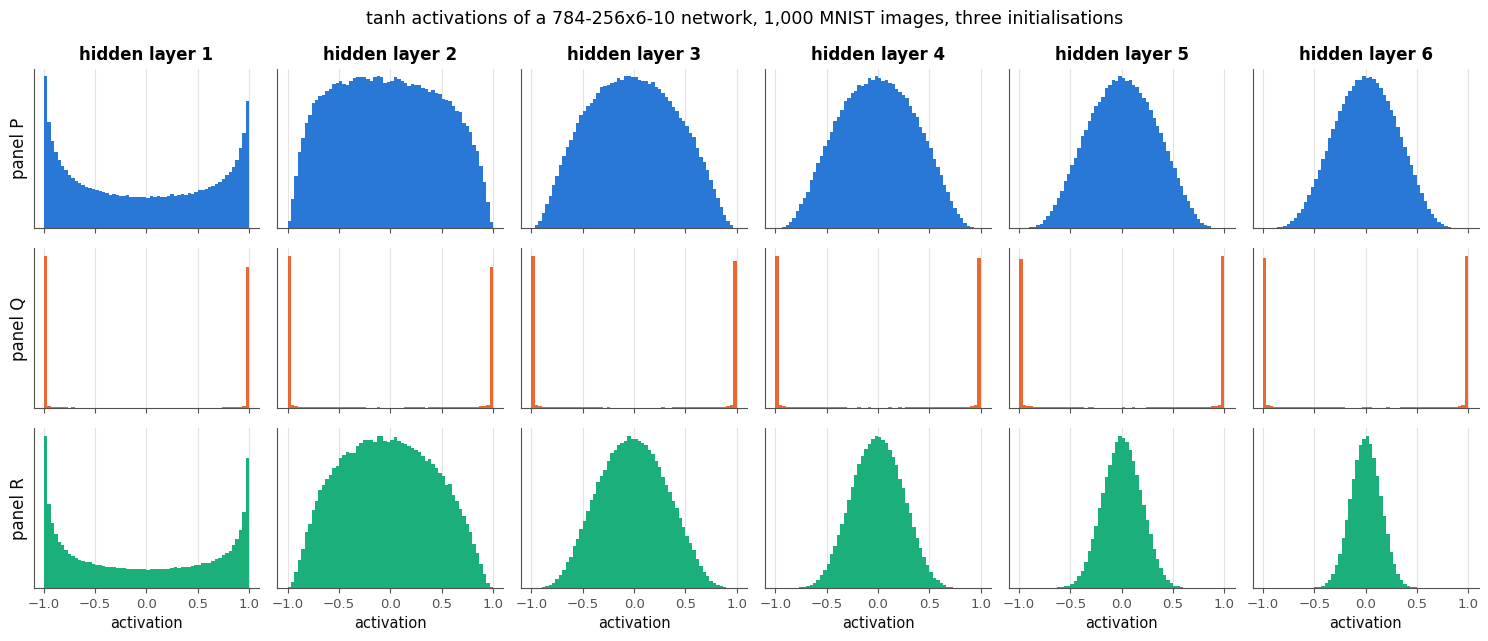

In [45]:
SIZES_22 = [784] + [256] * 6 + [10]          # six hidden layers of 256 tanh neurons
CANDIDATES_22 = [("normal", 0.05), ("glorot_normal", None), ("normal", 1.0)]
INITS_22 = dict(zip("PQR", [CANDIDATES_22[k] for k in np.random.default_rng(22).permutation(3)]))   # shuffled: read the figure


def activations_22(method, scale, X):
    """The tanh activations of the six hidden layers, for normal weights (zero biases): std `scale`, or the std of
    Glorot normal when scale is None."""
    rng = np.random.default_rng(1622)
    a, out = X, []
    for n_in, n_out in zip(SIZES_22[:-1], SIZES_22[1:]):
        std = np.sqrt(2 / (n_in + n_out)) if scale is None else scale
        a = np.tanh(a @ rng.normal(0.0, std, size=(n_in, n_out)))
        out.append(a)
    return out[:-1]                              # the six hidden layers (the 10 outputs are left out)


fig, axes = plt.subplots(3, 6, figsize=(15, 6.5), sharex=True)
for row, (panel, (method, scale)) in enumerate(INITS_22.items()):
    for layer, a in enumerate(activations_22(method, scale, X_STD[:1000])):
        axes[row, layer].hist(a.ravel(), bins=60, range=(-1, 1), density=True, color=f"C{row}")
        axes[row, layer].set_yticks([])
        if row == 0:
            axes[row, layer].set_title(f"hidden layer {layer + 1}")
    axes[row, 0].set_ylabel(f"panel {panel}", fontsize=12)
for ax in axes[-1]:
    ax.set_xlabel("activation")
fig.suptitle("tanh activations of a 784-256x6-10 network, 1,000 MNIST images, three initialisations")
fig.tight_layout()
plt.show()

In [46]:
panels_22, saturated_22, std_n005_22, glorot_flat_22 = "RPQ", True, "B", False   # read on the figure
print_answer("16.22a", panels_22)
print_answer("16.22b", saturated_22)
print_answer("16.22c", std_n005_22)
print_answer("16.22d", glorot_flat_22)

16.22a: RPQ
16.22b: True
16.22c: B
16.22d: False


In [47]:
a6_22 = {panel: activations_22(method, scale, X_STD[:1000])[-1] for panel, (method, scale) in INITS_22.items()}
std_22 = {panel: float(a.std()) for panel, a in a6_22.items()}
print("std of the layer-6 activations:", {p: round(s, 3) for p, s in std_22.items()},
      "· saturated with N(0, 1):", round(float(np.mean(np.abs(a6_22["Q"]) > 0.99)), 3))
wb.record("16.22a", "RPQ", mistakes={"l'échelle fixe 0,05 fait-elle grandir ou rétrécir les activations, couche après couche ?": "PRQ",
                                     "avec N(0, 1), les sommes pondérées de 784 ou 256 entrées sont énormes : où se voit la saturation ?": "RQP",
                                     "cherche d'abord le panneau saturé (des pics en ±1), puis celui qui rétrécit le plus vite": "QPR",
                                     "relis l'ordre demandé : N(0 ; 0,05²), puis Glorot, puis N(0 ; 1)": "QRP"})
wb.record("16.22b", True, mistakes={"regarde la couche 6 du panneau saturé : où se trouve presque toute la masse de l'histogramme ?": False})
wb.record("16.22c", "B", mistakes={"l'histogramme de la couche 6 de N(0 ; 0,05²) est étroit, mais il n'est pas réduit à un trait": "A",
                                   "compare la largeur de l'histogramme de la couche 6 à celle de la couche 1 : il a nettement rétréci": "C",
                                   "un écart-type de plus de 0,6, c'est presque toute la largeur [−1, 1]": "D"})
wb.record("16.22d", False, mistakes={"compare la largeur des histogrammes de Glorot entre la couche 1 et la couche 6": True})

std of the layer-6 activations: {'P': 0.294, 'Q': 0.974, 'R': 0.144} · saturated with N(0, 1): 0.866
WB_ANSWER {"hash": "10eaaaccdec1cada3c627747bff464ef4420c023a9e8f63c1be066417ef22961", "id": "16.22a", "kind": "str", "mistakes": {"7eb1e127b24f302b1ebc10bb811d3a10d3f305199e8d3a5680f859d6a9ca8557": "l'échelle fixe 0,05 fait-elle grandir ou rétrécir les activations, couche après couche ?", "951a4980b50cf5a25320ae21ab9114c98c69f36569c1bb66ff53684302e75b2b": "relis l'ordre demandé : N(0 ; 0,05²), puis Glorot, puis N(0 ; 1)", "ab94e8a67dd6a1d827f00530b91d47a7839f3b6676798ae25200b1da86c7c41e": "cherche d'abord le panneau saturé (des pics en ±1), puis celui qui rétrécit le plus vite", "fb4631a2e0e7bc91ce8fa454a4add158159e6921123f4bbc99503518f839c7c7": "avec N(0, 1), les sommes pondérées de 784 ou 256 entrées sont énormes : où se voit la saturation ?"}}
📝 Ex 16.22a : réponse enregistrée (str).
WB_ANSWER {"hash": "57099e98037c0fdcf49d92977687e44c2341e06d08d1b0a0b2145edb6c0f8fa8", "id": "16.22b

💡 R est $\mathcal{N}(0 ;\ 0{,}05^2)$, P Glorot et Q $\mathcal{N}(0 ;\ 1)$. Avec $\mathcal{N}(0 ;\ 1)$, une somme de 784 produits a un écart-type d'environ 28 : tanh renvoie presque toujours $\pm 1$ dès la couche 1, et 87 % des activations de la couche 6 sont saturées. Avec $\mathcal{N}(0 ;\ 0{,}05^2)$, le gain d'une couche de 256 entrées vaut $256 \times 0{,}05^2 = 0{,}64$ : l'écart-type est multiplié par $\sqrt{0{,}64} = 0{,}8$ environ à chaque couche (de 0,72 à 0,14 en six couches). Avec Glorot, il baisse aussi, mais lentement (de 0,68 à 0,29) : la règle suppose une activation linéaire près de 0, alors que tanh écrase un peu chaque valeur ($|\tanh z| < |z|$), si bien que chaque couche perd un peu de variance. C'est l'une des observations de Glorot et Bengio (📄 16.10).

### Ex 16.23 — Activations à travers 20 couches selon l'initialisation 🔬 ★★★ ⏱️ 45 min
**Objectif :** mesurer, couche par couche, l'écart-type des sommes pondérées de réseaux profonds pour quatre initialisations et deux activations.  
**Prérequis :** Ex 16.17 · Ex 16.14 · ∂ 16.7 · fiche, section sur le diagnostic · **Fil rouge :** MNIST · **Parcours :** M, C

Un réseau de 20 couches denses de 256 neurones (`SIZES_23`) reçoit 512 images MNIST standardisées (`X_23`). On fait varier son initialisation (`METHODS_23` : $\mathcal{N}(0 ;\ 0{,}05^2)$, LeCun, Glorot et He, toutes normales, biais nuls) et son activation (ReLU ou tanh, appliquée à **toutes** les couches).

Écris :
- `profile_23(activation, method, X, rng)` : initialise le réseau avec **ton** `init_weights` (avec `scale=0.05` pour `"normal"`), en tirant les couches dans l'ordre avec le générateur `rng`, lance **ton** `mlp_forward` sur `X` (l'activation passée à la fois en `activation` et en `output_activation`) et rend la liste des 20 écarts-types des sommes pondérées $z$, couche par couche (des `float` Python) ;
- `dead_23(X, rng)` : pour le réseau ReLU initialisé en He par **ton** `init_mlp`, la part des 256 neurones de la **dernière** couche dont la somme pondérée est $\le 0$ pour toutes les lignes de `X` (morts sur ce batch).

La vérification calcule les huit profils, les trace (échelle logarithmique), contrôle deux propriétés attendues en ReLU, puis vérifie que la part des neurones morts est entre 10 % et 50 %. Cet exercice se corrige avec `05_solutions.md`.

Dans tes notes : pour chaque activation, classe les quatre initialisations, et relie chaque pente à un gain de ∂ 16.7. En tanh, pourquoi He, de gain 2, garde-t-elle un écart-type plus grand que LeCun et Glorot, sans exploser ? La part des neurones morts dépend-elle de l'initialisation, à graine égale ? Pourquoi ?

In [48]:
X_23 = X_STD[:512]                                    # 512 standardized images
SIZES_23 = [784] + [256] * 20                         # 20 dense layers of 256 neurons
ACTIVATIONS_23 = {"relu": relu, "tanh": np.tanh}
METHODS_23 = ["normal", "lecun_normal", "glorot_normal", "he_normal"]   # "normal": N(0, 0.05²), as in the book

✅ Ex 16.23 : huit profils de 20 écarts-types (des float Python positifs).


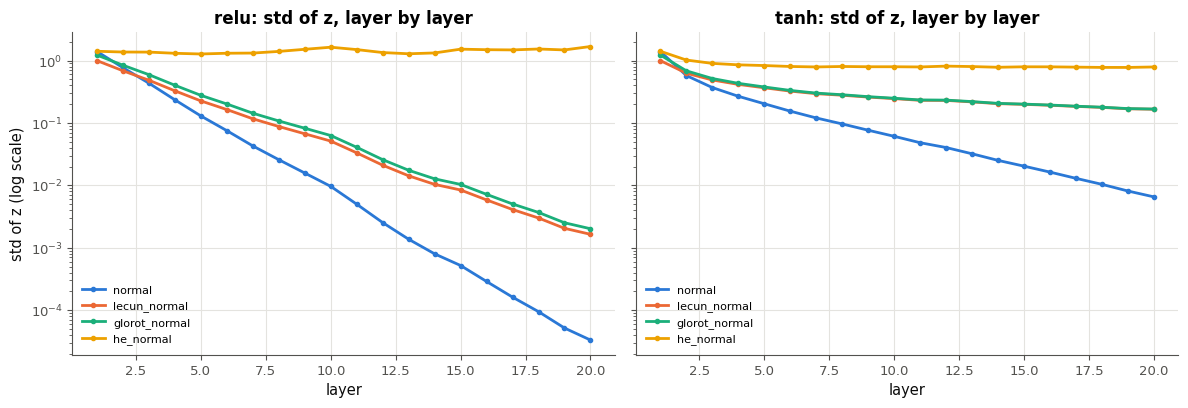

✅ Ex 16.23 : ReLU : He garde l'écart-type sur 20 couches, LeCun le divise par plus de 100.
ReLU + He, last layer: 28.9% of the neurons are dead on these 512 images
✅ Ex 16.23 : une part de neurones morts entre 10 % et 50 %, comme attendu à cette profondeur (la valeur exacte dépend des tirages).


In [49]:
def profile_23(activation, method, X, rng):
    """Initialise a network of sizes SIZES_23 with YOUR init_weights (method; scale=0.05 for "normal") and zero
    biases, drawing the layers in order from the generator rng, run YOUR mlp_forward on X with `activation` on every
    layer (pass it as both activation and output_activation), and return the list of the 20 standard deviations of
    the pre-activations z, layer by layer (Python floats)."""
    extra = {"scale": 0.05} if method == "normal" else {}
    params = [(mylearn.nn.layers.init_weights(a, b, method, rng, **extra), np.zeros(b))
              for a, b in zip(SIZES_23[:-1], SIZES_23[1:])]
    _, cache = mylearn.nn.layers.mlp_forward(X, params, activation=activation, output_activation=activation,
                                             return_cache=True)
    return [float(np.std(z)) for _, z in cache]


def dead_23(X, rng):
    """For a ReLU network of sizes SIZES_23 initialised with "he_normal" (YOUR init_mlp), return the fraction of the
    256 neurons of the LAST layer whose pre-activation z is <= 0 for every row of X (dead on this batch)."""
    params = mylearn.nn.layers.init_mlp(SIZES_23, "he_normal", rng)
    _, cache = mylearn.nn.layers.mlp_forward(X, params, activation=relu, output_activation=relu, return_cache=True)
    return float(np.mean((cache[-1][1] <= 0).all(axis=0)))
if True:
    profiles_23 = {(name, method): profile_23(f, method, X_23, np.random.default_rng(1623))
                   for name, f in ACTIVATIONS_23.items() for method in METHODS_23}
    shapes_ok_23 = all(len(p) == 20 and all(isinstance(s, float) and s >= 0 for s in p) for p in profiles_23.values())
    verdict("16.23", shapes_ok_23, "huit profils de 20 écarts-types (des float Python positifs).",
            "chaque profil doit être une liste de 20 float Python positifs, un par couche.")
    if shapes_ok_23:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
        for ax, name in zip(axes, ACTIVATIONS_23):
            for method in METHODS_23:
                ax.plot(range(1, 21), profiles_23[(name, method)], marker="o", ms=3, label=method)
            ax.set_yscale("log")
            ax.set_title(f"{name}: std of z, layer by layer")
            ax.set_xlabel("layer")
            ax.legend(fontsize=8)
        axes[0].set_ylabel("std of z (log scale)")
        fig.tight_layout()
        plt.show()
        he_23, lecun_23 = profiles_23[("relu", "he_normal")], profiles_23[("relu", "lecun_normal")]
        verdict("16.23", 0.5 < he_23[-1] / he_23[0] < 2 and lecun_23[-1] / lecun_23[0] < 0.01,
                "ReLU : He garde l'écart-type sur 20 couches, LeCun le divise par plus de 100.",
                "attendu en ReLU : avec He, un rapport dernière/première couche entre 0,5 et 2 ; avec LeCun, sous 0,01. "
                "Tires-tu chaque couche avec le même générateur, et passes-tu ReLU à toutes les couches ?")
if True:
    dead_found_23 = dead_23(X_23, np.random.default_rng(1623))
    if returned("16.23", "dead_23", dead_found_23):
        print(f"ReLU + He, last layer: {float(dead_found_23):.1%} of the neurons are dead on these 512 images")
        verdict("16.23", 0.1 < float(dead_found_23) < 0.5,
                "une part de neurones morts entre 10 % et 50 %, comme attendu à cette profondeur (la valeur exacte dépend des tirages).",
                "attendu : une part (entre 0 et 1) de neurones morts entre 0,1 et 0,5 ; compte-t-on bien les colonnes de la "
                "dernière somme pondérée qui sont <= 0 sur TOUTES les lignes ?")

In [50]:
profiles_ref_23 = {(name, method): profile_23(f, method, X_23, np.random.default_rng(1623))
                   for name, f in ACTIVATIONS_23.items() for method in METHODS_23}
for (name, method), p in profiles_ref_23.items():
    print(f"{name:5} {method:14} first layer {p[0]:.3f} · last layer {p[-1]:.3g} · ratio {p[-1] / p[0]:.3g}")

relu  normal         first layer 1.396 · last layer 3.31e-05 · ratio 2.37e-05
relu  lecun_normal   first layer 0.997 · last layer 0.00164 · ratio 0.00165
relu  glorot_normal  first layer 1.224 · last layer 0.00202 · ratio 0.00165
relu  he_normal      first layer 1.410 · last layer 1.68 · ratio 1.19
tanh  normal         first layer 1.396 · last layer 0.00654 · ratio 0.00468
tanh  lecun_normal   first layer 0.997 · last layer 0.166 · ratio 0.167
tanh  glorot_normal  first layer 1.224 · last layer 0.167 · ratio 0.137
tanh  he_normal      first layer 1.410 · last layer 0.79 · ratio 0.56


💡 En ReLU, He garde l'écart-type de 1,41 à 1,68 sur 20 couches (gain $2 \times \frac12 = 1$) ; LeCun et Glorot (identiques pour des couches carrées) le divisent par environ 600 (gain $\frac12$ par couche, soit $\sqrt{2}$ sur l'écart-type : $2^{-19/2} \approx 0{,}0014$) ; $\mathcal{N}(0 ;\ 0{,}05^2)$ par 40 000 (gain $256 \times 0{,}0025 \times \frac12 = 0{,}32$). En tanh, LeCun et Glorot baissent lentement (de 1 à 0,17) : tanh écrase un peu chaque valeur ; He, de gain 2, ferait grandir l'écart-type d'un réseau linéaire, mais tanh sature et borne ses sorties à $\pm 1$ : après une baisse de 1,4 à 1 en deux couches, le profil se stabilise vers 0,8, au prix d'activations plus saturées. La part des neurones morts (28,9 % ici, une valeur qui dépend des tirages) ne dépend pas de l'échelle, à graine égale et biais nuls : multiplier tous les poids par une constante positive ne change le signe d'aucune somme pondérée (ReLU est positivement homogène). Ce sont les corrélations entre les images, de plus en plus fortes avec la profondeur, qui tuent des neurones ; l'échelle n'y peut rien.

### Ex 16.24 — Défi : garder vivant un réseau ReLU de 50 couches 🏆 ★★★ ⏱️ 60 min
**Objectif :** trouver une initialisation qui garde vivant un réseau ReLU très profond, sans standardiser les données.  
**Prérequis :** Ex 16.23 · fiche, section sur le diagnostic (« Les données comptent aussi ») · **Fil rouge :** MNIST · **Parcours :** C

**Énoncé** : un réseau ReLU de 50 couches (`SIZES_24` : 784 pixels, 49 couches cachées de 128 neurones, 10 logits) reçoit des pixels **bruts** (de 0 à 255, sans standardisation). Écris `init_24(layer_sizes, X_sample, rng)`, qui rend ses paramètres, une liste de 50 couples `(W, b)` aux formes de la convention du chapitre, tels que, sur 1 000 images **de contrôle** que ta fonction ne voit pas (`X_HELD_24`), et pour chacune des trois graines de `SEEDS_24` : l'écart-type des sommes pondérées $z$ de **chaque** couche cachée, et celui des logits, soit compris entre 0,5 et 2 ; et moins de 10 % des neurones cachés soient morts (une somme pondérée $\le 0$ pour toutes les images de contrôle). Palier 🌟 : tous les écarts-types entre 0,8 et 1,25.

Règles : ta fonction peut regarder `X_sample` (1 000 autres images brutes) et tirer des nombres avec `rng`, et rien d'autre (ni `X_HELD_24`, ni l'état global `np.random`) ; tu peux utiliser tes fonctions de `mylearn.nn.layers`. Pour te situer : `init_mlp(SIZES_24, "he_normal", rng)` donne des écarts-types de 55 à 255 et 22 % à 27 % de neurones morts. La vérification mesure tout elle-même, en NumPy, sur les images de contrôle. Ce défi se corrige avec `05_solutions.md`.

Dans tes notes : ce que tu as essayé, dans l'ordre, et ce que chaque essai a changé aux trois mesures ; pourquoi régler seulement l'échelle de chaque couche ne suffit pas.

In [51]:
X_RAW_24, _ = wb.datasets.load_mnist("train", n=3000, flatten=True, seed=1624)
X_RAW_24 = X_RAW_24.astype(float)                       # RAW pixels, from 0 to 255: no standardization
X_SAMPLE_24, X_HELD_24 = X_RAW_24[:1000], X_RAW_24[1000:2000]
SIZES_24 = [784] + [128] * 49 + [10]                    # 49 hidden ReLU layers of 128 neurons + 10 logits: 50 layers
SEEDS_24 = [0, 1, 2]


def measure_24(params, X):
    """(std of z of each hidden layer, std of the logits, fraction of hidden neurons dead on X), computed here with
    NumPy only: z <= 0 on every row of X means dead."""
    a, stds, dead = X, [], []
    for k, (W, b) in enumerate(params):
        z = a @ np.asarray(W, dtype=float) + np.asarray(b, dtype=float)
        stds.append(float(z.std()))
        if k < len(params) - 1:
            dead.append((z <= 0).all(axis=0))
            a = np.maximum(0.0, z)
    return stds[:-1], stds[-1], float(np.mean(np.concatenate(dead)))

In [52]:
def init_24(layer_sizes, X_sample, rng):
    """Return a list of (W, b) for the ReLU network `layer_sizes` (W of shape (n_in, n_out), b of shape (n_out,)),
    chosen so that the network stays alive on raw MNIST pixels. You may look at X_sample (raw pixels, shape
    (1000, 784)) and draw random numbers from rng only."""
    params, a = [], np.asarray(X_sample, dtype=float)
    for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
        W = mylearn.nn.layers.init_weights(n_in, n_out, "he_normal", rng)
        z = a @ W
        b = -z.mean(axis=0) + 0.5 * z.std(axis=0)  # each neuron: mean at +0.5 of its own std (active on most images)
        scale = (z + b).std()                       # one scale per layer: unit variance on the sample (LSUV)
        W, b = W / scale, b / scale
        params.append((W, b))
        a = np.maximum(0.0, a @ W + b)
    return params
if True:
    results_24 = {}
    for seed_24 in SEEDS_24:
        params_24 = init_24(SIZES_24, X_SAMPLE_24.copy(), np.random.default_rng(seed_24))
        if not returned("16.24", "init_24", params_24):
            break
        shapes_24 = [(np.shape(W), np.shape(b)) for W, b in params_24]
        expected_24 = [((a, b), (b,)) for a, b in zip(SIZES_24[:-1], SIZES_24[1:])]
        if shapes_24 != expected_24:
            print("❌ Ex 16.24 : init_24 doit rendre 50 couples (W, b), W de forme (n_in, n_out) et b de forme (n_out,).")
            break
        with np.errstate(all="ignore"):
            results_24[seed_24] = measure_24(params_24, X_HELD_24)
    if len(results_24) == len(SEEDS_24):
        for seed_24, (hidden_24, logits_24, dead_24) in results_24.items():
            print(f"seed {seed_24}: std of the hidden layers from {min(hidden_24):.3f} to {max(hidden_24):.3f} · "
                  f"std of the logits {logits_24:.3f} · dead neurons {dead_24:.1%}")
        lows_24 = [min(min(h), l) for h, l, _ in results_24.values()]
        highs_24 = [max(max(h), l) for h, l, _ in results_24.values()]
        deads_24 = [d for _, _, d in results_24.values()]
        ok_24 = all(np.isfinite(lows_24 + highs_24)) and min(lows_24) >= 0.5 and max(highs_24) <= 2 and max(deads_24) < 0.10
        star_24 = ok_24 and min(lows_24) >= 0.8 and max(highs_24) <= 1.25
        verdict("16.24", ok_24,
                "défi réussi : sur les 1 000 images de contrôle et les trois graines, chaque couche a un écart-type entre "
                "0,5 et 2, et moins de 10 % des neurones sont morts." + (" 🌟 Palier atteint : tous entre 0,8 et 1,25." if star_24 else ""),
                f"écarts-types de {fr(min(lows_24))} à {fr(max(highs_24))} (attendu : entre 0,5 et 2), neurones morts "
                f"jusqu'à {fr(100 * max(deads_24), 1)} % (attendu : moins de 10 %) : relis la section de la fiche sur le "
                "diagnostic, en particulier « Les données comptent aussi ».")

seed 0: std of the hidden layers from 0.982 to 1.018 · std of the logits 1.023 · dead neurons 0.0%
seed 1: std of the hidden layers from 0.992 to 1.012 · std of the logits 0.987 · dead neurons 0.0%
seed 2: std of the hidden layers from 0.984 to 1.017 · std of the logits 1.014 · dead neurons 0.0%
✅ Ex 16.24 : défi réussi : sur les 1 000 images de contrôle et les trois graines, chaque couche a un écart-type entre 0,5 et 2, et moins de 10 % des neurones sont morts. 🌟 Palier atteint : tous entre 0,8 et 1,25.


💡 Le corrigé réussit le défi et le palier : sur les images de contrôle, des écarts-types de 0,98 à 1,02 et aucun neurone mort, pour les trois graines (et pour dix graines essayées). Il combine deux idées, mesurées sur les images de contrôle. L'**échelle** réglée sur les données (LSUV) : diviser chaque couche par l'écart-type de ses sommes pondérées sur l'échantillon ramène les écarts-types de 55 à 255 vers 1, mais laisse 22 % à 27 % de neurones morts. Le **biais** de chaque neurone : des pixels bruts sont tous positifs, comme les sorties de ReLU, si bien que la somme pondérée d'un neurone a une moyenne loin de 0, positive ou négative selon ses poids ; un neurone de moyenne très négative est mort pour toutes les images. Un biais qui place cette moyenne à $+0{,}5$ fois l'écart-type du neurone (mesurés sur l'échantillon) le rend actif sur environ 70 % des images, et plus aucun n'est mort. Centrer exactement (moyenne 0) suffit pour les neurones morts, mais pas pour le palier : chaque couche coupe alors la moitié de chaque neurone, le réseau amplifie les petites différences entre l'échantillon et les images de contrôle, et leurs écarts-types montent au-delà de 1,7 pour certaines graines. `05_solutions.md` donne les essais intermédiaires.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu calculer à la main la passe avant d'un petit MLP, et donner la forme de chaque tableau d'une passe avant sur un mini-batch ?
2. Sais-tu compter de tête les paramètres et la mémoire d'un réseau dense ?
3. Sais-tu expliquer pourquoi on n'initialise pas les poids à une constante, choisir entre He et Glorot, et vérifier ce choix en mesurant les activations couche par couche ?

**Pour aller plus loin** : les articles de Glorot et Bengio (2010) et de He et coll. (2015), et l'initialisation LSUV de Mishkin et Matas (2016), cités dans la fiche. La suite : le ch. 17, qui ouvre la boîte noire des fonctions d'activation, puis le ch. 18, où le cache de ton `mlp_forward` servira à la rétropropagation.